# EDA — Detección de "Fraude" (Mercado Libre)

## Paso 0 — Carga de datos

El ejercicio indica punto como decimal y **coma como separador de miles**.


In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from scipy import stats
from scipy.stats import rankdata
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")

# El CSV no se versiona (ver README): se busca hacia arriba desde la carpeta del cuaderno.
NOMBRE_CSV = "mercadolibre_fraud_dataset_data.csv"
RUTA = "/Users/santiagomartinez/Documents/proceso_meli/prueba/mercadolibre_fraud_dataset_data.csv"
SEED = 42
TARGET = "Fraude"

def wilson(k, n, alpha=0.05):
    """Intervalo de confianza de Wilson para una proporción k/n."""
    ci = stats.binomtest(int(k), int(n)).proportion_ci(confidence_level=1 - alpha, method="wilson")
    return ci.low, ci.high

In [3]:
# shape
df = pd.read_csv(RUTA, thousands=",")
print("Forma:", df.shape)
print(df.dtypes.value_counts().to_string())

Forma: (16880, 21)
int64      12
float64     8
str         1


In [4]:
df.dtypes

A           int64
B           int64
C         float64
D           int64
E           int64
F         float64
G         float64
H           int64
I           int64
J             str
K         float64
L           int64
M           int64
N           int64
O           int64
P           int64
Q         float64
R         float64
S         float64
Monto     float64
Fraude      int64
dtype: object

In [5]:
df.head(5)

,A,B,C,D,E,F,G,H,I,J,K,L,M,N,O,P,Q,R,S,Monto,Fraude
0,0,10,"50,257.0000",0,0,0.0000,0.0000,0,0,UY,0.8000,0,3,1,0,5,0.0000,0.0000,7.2500,37.5100,1
1,0,10,"29,014.0000",0,0,0.0000,0.0000,0,0,UY,NaN,0,1,1,0,3,0.0000,0.0000,11.6600,8.1800,1
2,0,7,92.0000,0,1,0.0000,0.0000,0,1,UY,NaN,0,3,1,0,2,0.0000,0.0000,86.9700,13.9600,1
3,9,16,"50,269.0000",0,0,0.0000,0.0000,0,0,UY,0.9100,0,3,1,0,5,0.0000,0.0000,2.5100,93.6700,1
4,0,8,"8,180.0000",0,0,0.0000,0.0000,0,0,UY,NaN,0,1,1,0,1,0.0000,0.0000,25.9600,135.4000,1


## Paso 1 — Partición train / test

Comprobamos si el archivo viene ordenado, porque eso condiciona cómo se puede dividir.

Partición 80/20 **estratificada** por `Fraude` con semilla fija. 


In [ ]:
primeras = df.head(1000)
print("Primeras 1000 filas -> tasa de fraude:", round(primeras[TARGET].mean(), 3), "| global:", round(df[TARGET].mean(), 3))
print(primeras["J"].value_counts(normalize=True).head(10).round(3).to_dict(), "(primeras 1000)")
print(df["J"].value_counts(normalize=True).head(10).round(3).to_dict(), "(global)")
# los primeros 1000 registros todos son fraude, lo que nos permite concluir que la tabla está ordenada.
# la tabla está desbalanceada, aproximadamente 70:30 a favor de no fraude. Esto es importante para la partición.

Primeras 1000 filas -> tasa de fraude: 1.0 | global: 0.273
{'ES': 0.295, 'AR': 0.234, 'US': 0.192, 'UY': 0.18, 'MX': 0.099} (primeras 1000)
{'AR': 0.553, 'BR': 0.262, 'MX': 0.14, 'ES': 0.019, 'US': 0.014, 'UY': 0.011, 'CA': 0.001, 'GB': 0.0, 'GT': 0.0, 'FR': 0.0} (global)


In [7]:
# Proponemos una partición estratificada 80/20. A partir de aquí solo se explora train.
train, test = train_test_split(df, test_size=0.20, stratify=df[TARGET], random_state=SEED)
train, test = train.reset_index(drop=True), test.reset_index(drop=True)

particion = pd.DataFrame({
    "filas": [len(df), len(train), len(test)],
    "fraudes": [df[TARGET].sum(), train[TARGET].sum(), test[TARGET].sum()],
    "tasa_fraude": [df[TARGET].mean(), train[TARGET].mean(), test[TARGET].mean()],
}, index=["total", "train", "test"])
particion

,filas,fraudes,tasa_fraude
total,16880,4611,0.2732
train,13504,3689,0.2732
test,3376,922,0.2731


**Conclusión paso 1**
- `train` = 13.504 filas y `test` = 3.376, con la misma tasa de fraude (27,32% y 27,31%): la estratificación funcionó.
- **El archivo está ordenado por la clase:** las primeras 1.000 filas son 100% fraude (el global es 27,3%) y su mezcla de países es distinta (ES, US, UY sobrerrepresentados).
- Desde aquí, todo se calcula sobre `train`.


## Paso 2 — Calidad de datos

Duplicados, tipos, rangos, valores centinela y variables casi constantes.


In [8]:
# PASO 2. Calidad de datos (sobre train)
print("Duplicados exactos en el dataset completo:", int(df.duplicated().sum()), "| en train:", int(train.duplicated().sum()))

cal = pd.DataFrame({
    "tipo": train.dtypes.astype(str),
    "únicos": train.nunique(),
    "min": train.select_dtypes("number").min(),
    "max": train.select_dtypes("number").max(),
    "negativos": (train.select_dtypes("number") < 0).sum(),
    "%moda": train.apply(lambda s: s.value_counts(normalize=True, dropna=True).iloc[0] * 100),
}).loc[train.columns]
cal

Duplicados exactos en el dataset completo: 1 | en train: 0


,tipo,únicos,min,max,negativos,%moda
A,int64,21,0.0000,30.0000,0.0000,84.4268
B,int64,21,-1.0000,20.0000,91.0000,7.8125
C,float64,8136,0.0000,"617,324.0000",0.0000,1.0089
D,int64,26,0.0000,180.0000,0.0000,94.2906
E,int64,23,0.0000,45.0000,0.0000,84.4713
F,float64,148,0.0000,1.0000,0.0000,88.3368
G,float64,95,0.0000,1.0000,0.0000,97.2305
H,int64,14,0.0000,21.0000,0.0000,98.3116
I,int64,17,0.0000,24.0000,0.0000,94.7571
J,str,15,NaN,NaN,NaN,55.4873


In [9]:
# Valores centinela (-1) y su relación con el fraude

filas = []
for col in ["B", "S"]:
    for nombre, mask in [(f"{col} = -1", train[col] == -1), (f"{col} != -1", train[col] != -1)]:
        k, n = train.loc[mask, TARGET].sum(), mask.sum()
        filas.append((nombre, n, k / n))
pd.DataFrame(filas, columns=["grupo", "n", "tasa_fraude"])

,grupo,n,tasa_fraude
0,B = -1,91,0.1648
1,B != -1,13413,0.2739
2,S = -1,112,0.5804
3,S != -1,13392,0.2706


In [ ]:
# Ceros por variable (train): cuántos registros valen exactamente 0 y qué proporción representan.
# Los NaN no cuentan como ceros: la proporción se da sobre el total de registros y sobre los registros con dato.
filas = []
for col in train.select_dtypes("number").columns.drop(TARGET):
    s = train[col]; ceros = s == 0
    filas.append({"variable": col, "registros": len(s), "con_dato": int(s.notna().sum()), "ceros": int(ceros.sum()),
                  "%_ceros_sobre_registros": ceros.mean() * 100,
                  "%_ceros_sobre_con_dato": ceros.sum() / s.notna().sum() * 100,
                  "tasa_fraude_con_cero": train.loc[ceros, TARGET].mean() if ceros.any() else np.nan,
                  "tasa_fraude_sin_cero": train.loc[s.notna() & ~ceros, TARGET].mean()})
ceros_tabla = pd.DataFrame(filas).set_index("variable").sort_values("ceros", ascending=False)
ceros_tabla

,registros,con_dato,ceros,%_ceros_sobre_registros,%_ceros_sobre_con_dato,tasa_fraude_con_cero,tasa_fraude_sin_cero
variable,,,,,,,
O,13504,13504,13400,99.2299,99.2299,0.2717,0.4615
R,13504,13504,13398,99.2150,99.2150,0.2720,0.4245
H,13504,13504,13276,98.3116,98.3116,0.2696,0.4825
G,13504,13504,13130,97.2305,97.2305,0.2708,0.3583
Q,13504,13504,12975,96.0826,96.0826,0.2666,0.4348
I,13504,13504,12796,94.7571,94.7571,0.2723,0.2895
D,13504,13504,12733,94.2906,94.2906,0.2680,0.3580
F,13504,13504,11929,88.3368,88.3368,0.2757,0.2540
E,13504,13504,11407,84.4713,84.4713,0.2682,0.3004


**Lectura de la tabla de ceros**
- 11 de las 19 variables numéricas tienen ceros: `O` (99,2%), `R` (99,2%), `H` (98,3%), `G` (97,2%), `Q` (96,1%), `I` (94,8%), `D` (94,3%), `F` (88,3%), `E` (84,5%), `A` (84,4%) y `L` (64,5%). `C` tiene 110 ceros (0,81% de los registros; 1,01% de los que tienen dato). `P`, `S`, `K`, `N`, `M`, `B` y `Monto` no tienen ceros.
- Para `C` y `K` los faltantes no cuentan como ceros: por eso la proporción se muestra sobre el total de registros y sobre los registros con dato (solo difieren en esas dos variables).
- En la mayoría de las variables dispersas, el valor distinto de cero se asocia con más fraude (27,2% con `O` = 0 frente a ~46% con `O` > 0; `R` ~42%, `H` ~48%, `Q` ~43%, `G` y `D` ~36%, `A` ~33%, `E` ~30%). En `I`, `F` y `L` casi no cambia. En `C`, los 110 ceros tienen 39,1% de fraude, pero son pocos.
- Los ceros son el valor más frecuente, no datos faltantes: se tratan con un indicador `x > 0` (paso 5).

**Conclusión paso 2**
- Duplicados: hay 1 par idéntico en todo el dataset (filas 271 y 272); en `train` no queda ningún duplicado exacto. Efecto despreciable (1 fila de 16.880), no se elimina nada.
- Los únicos negativos son los `-1` de `B` (91 filas) y `S` (112 filas).
- **El `-1` es informativo, no un error:** con `S = -1` el fraude es 58,0% frente a 27,1% en el resto, y con `B = -1` es 16,5% frente a 27,4%. **[H]** el `-1` codifica "no disponible / no calculable".
- Variables casi constantes (≥ 97% en un valor): `O` (99,2%), `R` (99,2%), `H` (98,3%) y `G` (97,2%). No se descartan todavía: que sean raras no implica que no tengan señal (se evalúa en el paso 7).
- `C` tiene 8.136 valores distintos en train y `Monto` 8.189: son continuas.

## Paso 3 — Variable objetivo


Fraude
No fraude    9815
Fraude       3689
Tasa de fraude: 27.32%
Razón de desbalance (neg:pos): 2.66:1


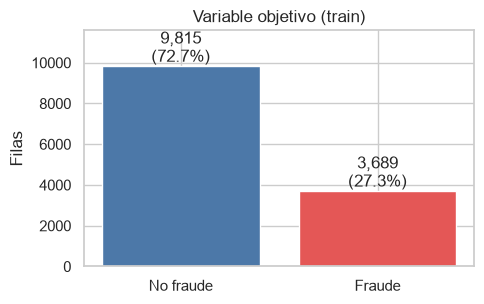

In [14]:
# PASO 3. Variable objetivo (train)
conteo = train[TARGET].value_counts().sort_index()
k, n = conteo[1], conteo.sum()
print(conteo.rename({0: "No fraude", 1: "Fraude"}).to_string())
print(f"Tasa de fraude: {k/n:.2%}")
print(f"Razón de desbalance (neg:pos): {conteo[0]/conteo[1]:.2f}:1")
#print(f"Línea base PR-AUC (clasificador aleatorio) = prevalencia = {k/n:.3f}")
#print(f"scale_pos_weight sugerido (neg/pos): {conteo[0]/conteo[1]:.2f}")

fig, ax = plt.subplots(figsize=(5, 3.2))
ax.bar(["No fraude", "Fraude"], conteo.values, color=["#4C78A8", "#E45756"])
for i, v in enumerate(conteo.values):
    ax.text(i, v, f"{v:,}\n({v/n:.1%})", ha="center", va="bottom")
ax.set_ylim(0, conteo.max() * 1.18); ax.set_title("Variable objetivo (train)"); ax.set_ylabel("Filas")
plt.tight_layout(); plt.show()

**Conclusión paso 3**
- Tasa de fraude 27,32%, razón negativos:positivos = 2,66:1. Hay un desbalance **moderado**, muy lejos del 0,1–1% que indica la literatura.
- Consecuencias para el modelado: no usar *accuracy* (un modelo que siempre dice "no fraude" acierta 72,7%); métrica principal **PR-AUC** (línea base = 0,273) junto con ROC-AUC, recall a precisión fija y matriz de confusión; validación cruzada estratificada; probar `class_weight` / `scale_pos_weight ≈ 2,66` como hiperparámetro, no como supuesto.


## Paso 4 — Datos faltantes

In [15]:
# Solo `C` y `K` tienen faltantes. Se estudia su magnitud, su relación con el fraude y su mecanismo.
falt = pd.DataFrame({"n_faltantes": train.isna().sum(), "pct_faltantes": train.isna().mean() * 100})
falt

,n_faltantes,pct_faltantes
A,0,0.0000
B,0,0.0000
C,2601,19.2610
D,0,0.0000
E,0,0.0000
F,0,0.0000
G,0,0.0000
H,0,0.0000
I,0,0.0000
J,0,0.0000


In [ ]:
# ¿El faltante se asocia con el fraude? prueba chi-cuadrado para probar independencia?
filas = []
for col in ["C", "K"]:
    falta = train[col].isna()
    tabla = pd.crosstab(falta, train[TARGET])
    chi2, p, _, _ = stats.chi2_contingency(tabla)
    for etiqueta, mask in [("falta", falta), ("presente", ~falta)]:
        k, n = train.loc[mask, TARGET].sum(), mask.sum()
        filas.append((col, etiqueta, n, k / n, chi2 if etiqueta == "falta" else np.nan, p if etiqueta == "falta" else np.nan))
res = pd.DataFrame(filas, columns=["var", "estado", "n", "tasa_fraude", "chi2", "p_valor"])
res["p_valor"] = res["p_valor"].map(lambda p: "" if pd.isna(p) else f"{p:.1e}")
res

# H0: el faltante y el fraude son independientes (chi-cuadrado, 1 g.l.).
# Resultado: K chi2 = 164,8 (p = 1,0e-37) y C chi2 = 156,0 (p = 8,5e-36): p < 0,05 en ambas, se rechaza H0.
# La ausencia está asociada al fraude: con el dato ausente hay menos fraude (K 24,6% vs 36,1%; C 17,5% vs 29,7%).

,var,estado,n,tasa_fraude,chi2,p_valor
0,C,falta,2601,0.1749,155.9939,8.5e-36
1,C,presente,10903,0.2966,NaN,
2,K,falta,10282,0.2456,164.7927,1.0e-37
3,K,presente,3222,0.3613,NaN,


In [ ]:
# Imputación de C con la mediana de train (más robusta que la media: C es muy asimétrica) + indicador de faltante.
mediana_C = train["C"].median()
train_imp, test_imp = train.copy(), test.copy()
for d in (train_imp, test_imp):
    d["C_falta"] = d["C"].isna().astype(int)      # la ausencia se asocia con el fraude (celda anterior)
    d["C"] = d["C"].fillna(mediana_C)

print(f"Mediana de C en train (sobre las filas con dato): {mediana_C:,.0f}")
print(f"Filas imputadas -> train: {int(train_imp['C_falta'].sum()):,} ({train_imp['C_falta'].mean():.1%}) | test: {int(test_imp['C_falta'].sum()):,} ({test_imp['C_falta'].mean():.1%})")
print("Faltantes de C tras imputar -> train:", int(train_imp["C"].isna().sum()), "| test:", int(test_imp["C"].isna().sum()))
pd.DataFrame({"mediana": [train["C"].median(), train_imp["C"].median()], "media": [train["C"].mean(), train_imp["C"].mean()]},
             index=["C original (con NaN)", "C imputada"])
# Se guarda en copias (train_imp, test_imp) para que el EDA siguiente analice el C original, sin 19% de filas con el mismo valor.
# La mediana sale solo de train y se aplica igual a test.

Mediana de C en train (sobre las filas con dato): 6,235
Filas imputadas -> train: 2,601 (19.3%) | test: 596 (17.7%)
Faltantes de C tras imputar -> train: 0 | test: 0


,mediana,media
C original (con NaN),"6,235.0000","39,267.6706"
C imputada,"6,235.0000","32,905.2613"


**Conclusión paso 4**
- Faltantes: `K` 76,14% (10.282 filas) y `C` 19,26% (2.601 filas); las otras 19 columnas están completas.
- **El faltante es informativo.** Fraude con `K` ausente 24,6% frente a 36,1% con `K` presente (χ² = 164,8; p ≈ 1e-37); con `C` ausente 17,5% frente a 29,7% (χ² = 156,0; p ≈ 1e-35). Con p < 0,05 en ambas, **se rechaza la independencia** entre faltante y fraude.

**Decisiones que se derivan:**
1. **No eliminar `K`**: aunque falte en 76%, su ausencia y su valor aportan señal.
2. Crear los indicadores `K_falta` y `C_falta`.
3. **Imputar `C` con la mediana de train** (más robusta que la media, porque `C` es muy asimétrica), junto con `C_falta`: el resultado queda en `train_imp` y `test_imp` (con la mediana de train también en test). El resto del EDA usa `train` sin imputar para no distorsionar la forma de `C`. `K` (76% de faltantes) se deja con NaN: los modelos de árboles lo manejan y los lineales usarán el indicador.

## Paso 5 — Univariado numérico

Forma de cada distribución: asimetría, curtosis, ceros, colas y efecto de `log1p`. Los `-1` de `B` y `S` (centinelas) se excluyen solo para describir la forma. **Normalidad:** con n ≈ 13.500 se usan asimetría, curtosis y Q-Q. **Outliers:** se miran con el p99 y se comprueba si la cola por encima del p99 es ruido o señal.


In [18]:
# PASO 5. Univariado numérico (train). Los -1 de B y S son centinelas: se excluyen de los estadísticos de forma.
CONTINUAS = ["C", "K", "F", "G", "Q", "R", "S", "Monto"]
DISCRETAS = ["A", "B", "D", "E", "H", "I", "L", "M", "N", "O", "P"]
NUM = CONTINUAS + DISCRETAS

X = train[NUM].copy()
for col in ["B", "S"]:
    X.loc[X[col] == -1, col] = np.nan        # centinela -> NaN solo para describir la forma

def describir_forma(s):
    s = s.dropna()
    return pd.Series({
        "n_valido": len(s), "media": s.mean(), "mediana": s.median(), "desv": s.std(),
        "asimetría": s.skew(), "curtosis": s.kurt(), "%ceros": (s == 0).mean() * 100,
        "p99": s.quantile(.99), "máx": s.max()
    })

tabla5 = X.apply(describir_forma).T
tabla5.insert(0, "tipo", ["continua"] * len(CONTINUAS) + ["discreta"] * len(DISCRETAS))
tabla5.sort_values("asimetría", ascending=False)

,tipo,n_valido,media,mediana,desv,asimetría,curtosis,%ceros,p99,máx
D,discreta,"13,504.0000",0.2042,0.0000,2.1746,50.0953,"3,675.4231",94.2906,4.0000,180.0000
R,continua,"13,504.0000",1.9544,0.0000,36.2879,30.5680,"1,203.9671",99.2150,0.0000,"2,025.7200"
H,discreta,"13,504.0000",0.0508,0.0000,0.5315,18.0185,458.2768,98.3116,2.0000,21.0000
Q,continua,"13,504.0000",8.4464,0.0000,75.5197,16.5422,348.9564,96.0826,235.8526,"2,263.4300"
O,discreta,"13,504.0000",0.0094,0.0000,0.1160,15.1645,277.7260,99.2299,0.0000,3.0000
G,continua,"13,504.0000",0.0054,0.0000,0.0607,14.6642,228.4626,97.2305,0.1149,1.0000
Monto,continua,"13,504.0000",160.9740,80.2300,278.2568,12.5264,373.5649,0.0000,"1,131.6890","12,538.4400"
A,discreta,"13,504.0000",0.3108,0.0000,1.1199,9.6570,162.5802,84.4268,5.0000,30.0000
I,discreta,"13,504.0000",0.1433,0.0000,0.8202,9.4519,133.9783,94.7571,4.0000,24.0000
F,continua,"13,504.0000",0.0159,0.0000,0.0994,8.5808,78.1381,88.3368,0.5000,1.0000


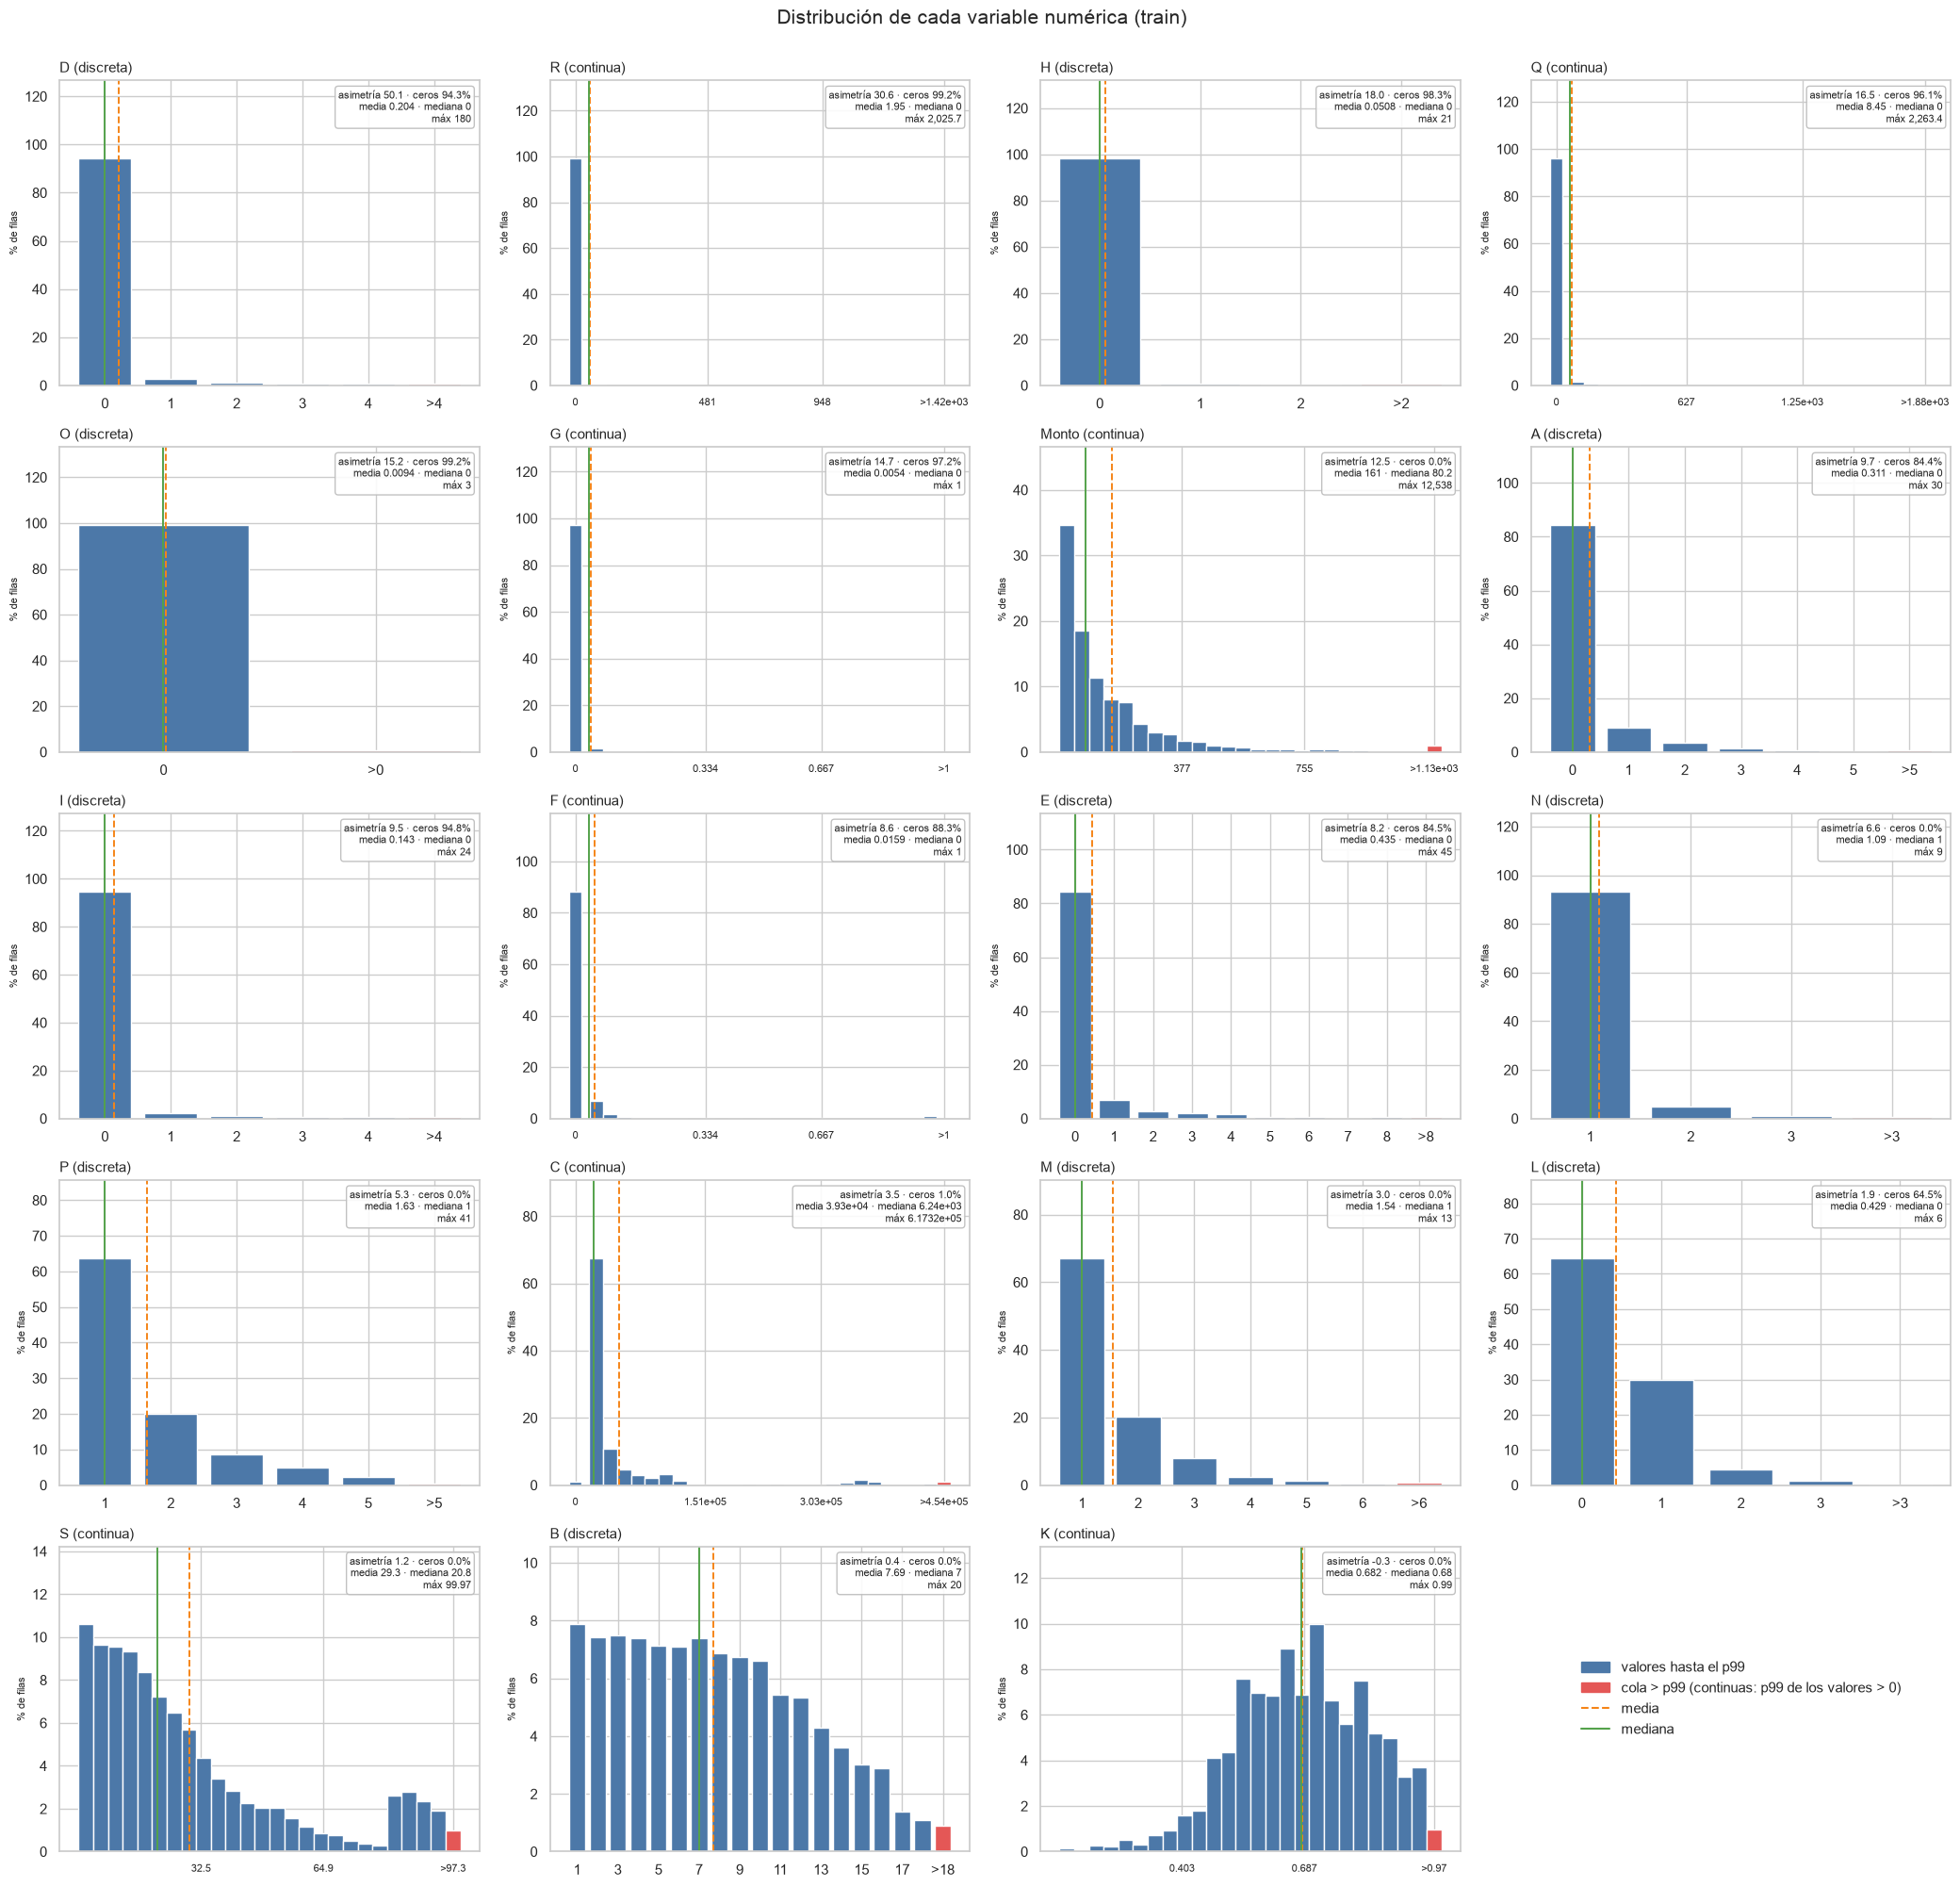

In [19]:
# Gráficos de barras de cada variable numérica, para comparar con la tabla del paso 5.

ORDEN = tabla5.sort_values("asimetría", ascending=False).index.tolist()
AZUL, ROJO = "#4C78A8", "#E45756"

def barras_variable(ax, nombre, logy=False):
    s = X[nombre].dropna(); n = len(s); fila = tabla5.loc[nombre]
    if fila["tipo"] == "discreta":                                   # una barra por valor, hasta el p99
        tope = int(np.ceil(s.quantile(.99))); niveles = np.arange(int(s.min()), tope + 1)
        pct = s[s <= tope].value_counts().reindex(niveles, fill_value=0) / n * 100
        ax.bar(niveles, pct.values, width=.8, color=AZUL)
        cola = (s > tope).sum() / n * 100
        ax.bar(tope + 1, cola, width=.8, color=ROJO)
        paso = max(1, len(niveles) // 8)
        marcas = [m for m in niveles[::paso] if m < tope + 1 - (paso > 1)] + [tope + 1]   # sin pisar la etiqueta de la cola
        ax.set_xticks(marcas); ax.set_xticklabels([str(int(m)) for m in marcas[:-1]] + [f">{tope}"])
        pos_cola = tope + 1
    else:                                                            # continua: barra de ceros + histograma de los positivos
        pos = s[s > 0]; p99 = pos.quantile(.99)
        bordes = np.linspace(pos.min(), p99, 26); w = bordes[1] - bordes[0]
        cuentas, _ = np.histogram(pos[pos <= p99], bins=bordes)
        centros = (bordes[:-1] + bordes[1:]) / 2
        ax.bar(centros, cuentas / n * 100, width=w, color=AZUL)
        marcas = []
        if (s == 0).any():
            ax.bar(-w, (s == 0).sum() / n * 100, width=w * .9, color=AZUL); marcas.append(-w)
        ax.bar(p99 + w / 2, (pos > p99).sum() / n * 100, width=w, color=ROJO)
        pos_cola = p99 + w / 2
        grid = list(np.linspace(pos.min(), p99, 4)[1:-1])                  # solo marcas interiores: evita solapes
        ax.set_xticks(marcas + grid + [pos_cola])
        ax.set_xticklabels(["0"] * len(marcas) + [f"{g:,.3g}" for g in grid] + [f">{p99:,.3g}"], fontsize=8)
    ax.axvline(fila["media"], color="#F58518", ls="--", lw=1.4)
    ax.axvline(fila["mediana"], color="#54A24B", lw=1.4)
    ax.set_title(f"{nombre} ({fila['tipo']})", fontsize=11, loc="left")
    ax.text(.98, .97, f"asimetría {fila['asimetría']:.1f} · ceros {fila['%ceros']:.1f}%\nmedia {fila['media']:,.3g} · mediana {fila['mediana']:,.3g}\nmáx {fila['máx']:,.5g}",
            transform=ax.transAxes, ha="right", va="top", fontsize=8, bbox=dict(boxstyle="round", fc="white", ec="#bbb", alpha=.9))
    ax.set_ylabel("% de filas", fontsize=8)
    if logy: ax.set_yscale("log"); ax.set_ylim(1e-3, 400)
    else: ax.set_ylim(0, ax.get_ylim()[1] * 1.28)

def panel_barras(logy=False):
    fig, axes = plt.subplots(5, 4, figsize=(21, 20))
    for ax, nombre in zip(axes.ravel(), ORDEN): barras_variable(ax, nombre, logy)
    leyenda = axes.ravel()[len(ORDEN)]; leyenda.axis("off")
    leyenda.legend(handles=[Patch(color=AZUL, label="valores hasta el p99"), Patch(color=ROJO, label="cola > p99 (continuas: p99 de los valores > 0)"),
                            Line2D([0], [0], color="#F58518", ls="--", label="media"), Line2D([0], [0], color="#54A24B", label="mediana")],
                   loc="center", fontsize=11, frameon=False)
    fig.suptitle("Distribución de cada variable numérica (train)" + (" — eje Y logarítmico" if logy else ""), y=1.0, fontsize=15)
    plt.tight_layout(); plt.show()

panel_barras(logy=False)

# Alturas = % de las filas válidas (train). Azul: valores hasta el p99; rojo: cola por encima del p99
# (en las continuas el p99 se calcula sobre los valores > 0, porque la barra de ceros ocupa casi todo).
# Línea naranja discontinua = media; línea verde = mediana. El recuadro repite las cifras de la tabla.

**Cómo leer estos gráficos (compáralos con la tabla)**
- La **barra de ceros** coincide con la columna `%ceros`: en `R` y `O` casi toda la altura está en 0 (99,2%), en `D` 94,3%, en `L` 64,5%.
- **Media y mediana separadas = asimetría:** `Monto` tiene media 161 y mediana 80; `C`, media 39.268 y mediana 6.235; en `D`, `R`, `H`, `Q`, `O` y `G` la mediana es 0 y la media es positiva. En `K` (media 0,68; mediana 0,68) y `B` (7,7 y 7) las líneas casi coinciden.
- **Barra roja = cola por encima del p99.** En las discretas agrupa los valores mayores al p99 de toda la variable; en las continuas, el 1% más alto de los valores positivos. El recuadro da el máximo, que está muy lejos de ese p99 (p. ej. `D`: p99 = 4 y máximo 180; `Q`: p99 = 236 y máximo 2.263).
- **Lo que la tabla no muestra y el gráfico logarítmico sí:** `C` tiene una segunda concentración de valores entre ~3,0×10⁵ y 4,5×10⁵ (una segunda «joroba»), que explica gran parte de su asimetría; `S` es la única con sesgo moderado y masa repartida (asimetría 1,2), `B` es plana y decreciente, y `K` es casi simétrica.
- Las únicas variables sin masa en cero ni cola pesada son `B`, `S` y `K`.

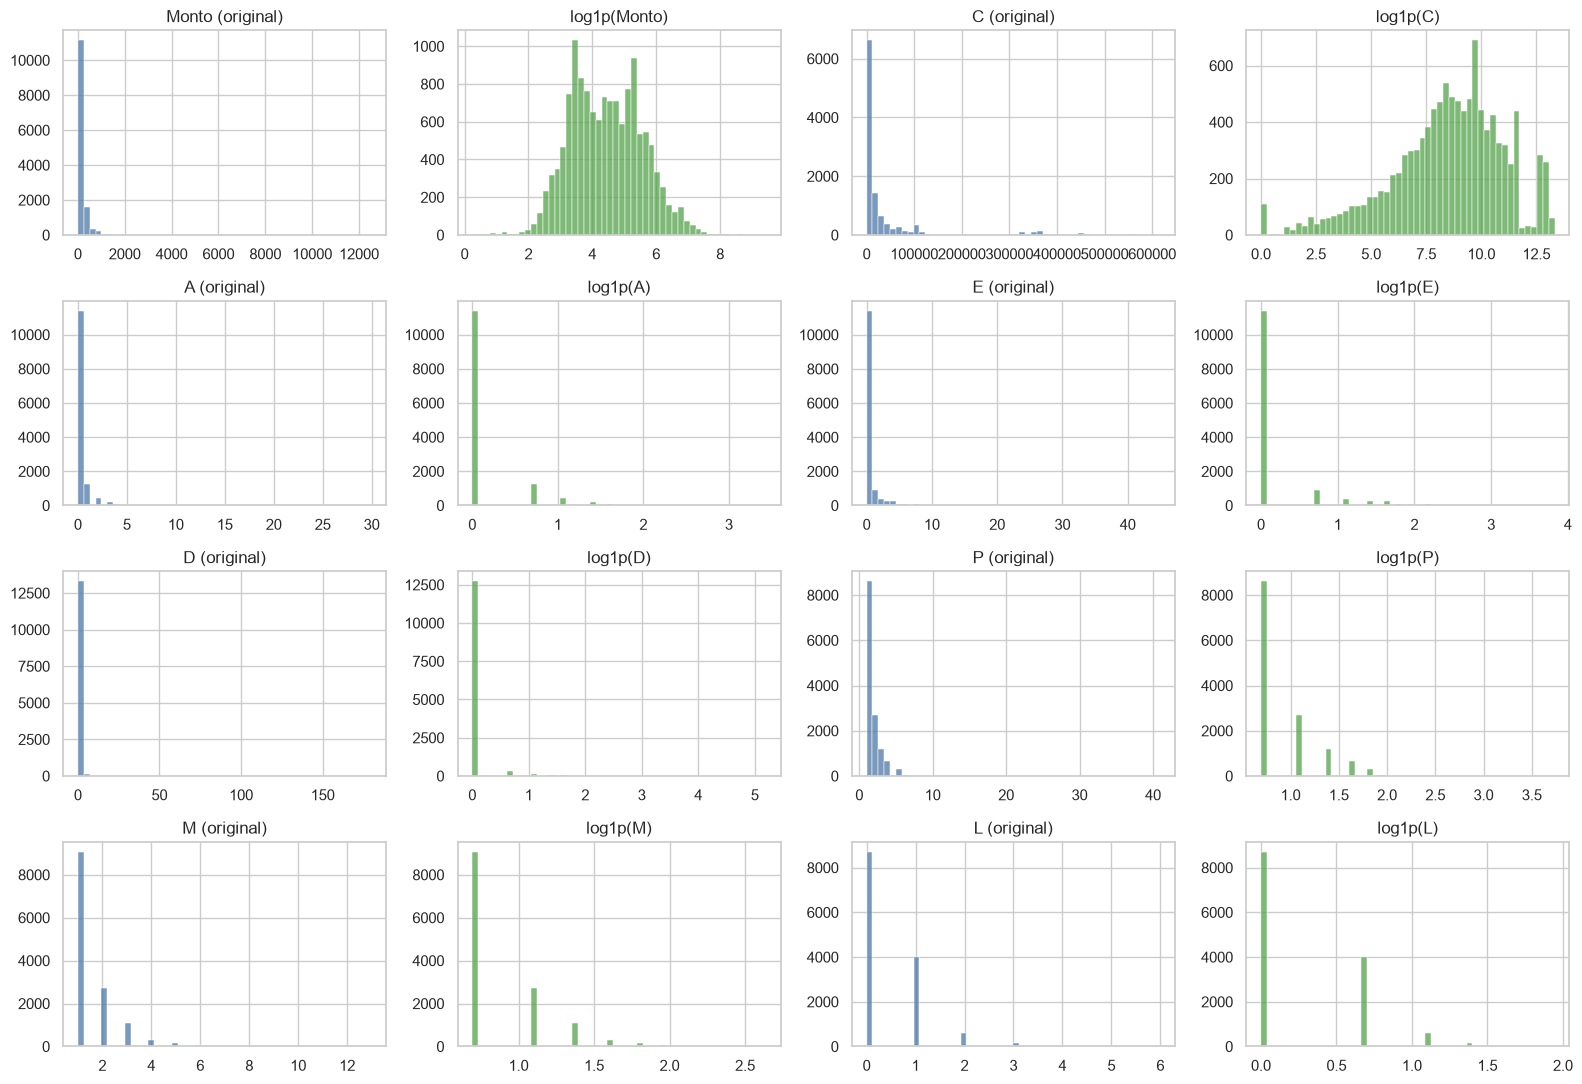

In [20]:
# Forma de las variables: original vs log1p para las más asimétricas
sesgadas = ["Monto", "C", "A", "E", "D", "P", "M", "L"]
fig, axes = plt.subplots(4, 4, figsize=(16, 11))
for i, col in enumerate(sesgadas):
    s = X[col].dropna()
    r, c = divmod(i, 2)
    sns.histplot(s, bins=50, ax=axes[r, c * 2], color="#4C78A8"); axes[r, c * 2].set_title(f"{col} (original)")
    sns.histplot(np.log1p(s), bins=50, ax=axes[r, c * 2 + 1], color="#54A24B"); axes[r, c * 2 + 1].set_title(f"log1p({col})")
    for a in (axes[r, c * 2], axes[r, c * 2 + 1]): a.set_xlabel(""); a.set_ylabel("")
plt.tight_layout(); plt.show()

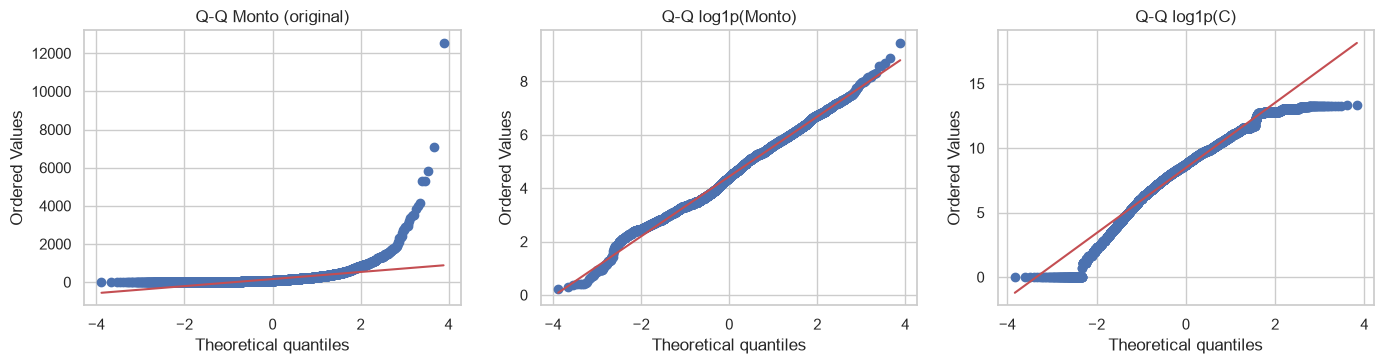

In [ ]:
# Normalidad: no se usa Shapiro (con n=13.500 rechazan siempre). Se mira asimetría, curtosis y Q-Q.
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
stats.probplot(X["Monto"].dropna(), dist="norm", plot=axes[0]); axes[0].set_title("Q-Q Monto (original)")
stats.probplot(np.log1p(X["Monto"].dropna()), dist="norm", plot=axes[1]); axes[1].set_title("Q-Q log1p(Monto)")
stats.probplot(np.log1p(X["C"].dropna()), dist="norm", plot=axes[2]); axes[2].set_title("Q-Q log1p(C)")
plt.tight_layout(); plt.show()
# Resultado (si los puntos siguen la recta, la variable es aproximadamente normal):
#  - Monto original: se separa mucho de la recta en la cola derecha (cola pesada): no es normal.
#  - log1p(Monto): casi sobre la recta: aproximadamente normal (log-normal).
#  - log1p(C): mejora, pero se aparta en ambos extremos (tope en 0 y en ~13): no es normal.

### ¿Los valores extremos son errores o señal?
En fraude las colas suelen ser justamente lo que se busca. Se compara la tasa de fraude en la cola (> p99) contra el resto, con chi².


In [22]:
# ¿Los valores extremos son errores o señal? Tasa de fraude en la cola superior (> p99) vs el resto
filas = []
for col in ["Monto", "C", "Q", "R", "A", "D", "E", "P", "N", "M"]:
    s = train[col]; ok = s.notna() & (s != -1)
    p99 = s[ok].quantile(.99)
    cola = ok & (s > p99); resto = ok & (s <= p99)
    if cola.sum() < 5: continue
    tabla = pd.crosstab(cola[ok], train.loc[ok, TARGET])
    p = stats.chi2_contingency(tabla)[1]
    filas.append((col, p99, cola.sum(), train.loc[cola, TARGET].mean(), train.loc[resto, TARGET].mean(), f"{p:.1e}"))
pd.DataFrame(filas, columns=["var", "p99", "n_cola", "fraude|cola>p99", "fraude|resto", "p_chi2"])

,var,p99,n_cola,fraude|cola>p99,fraude|resto,p_chi2
0,Monto,"1,131.6890",136,0.2353,0.2736,3.7e-01
1,C,"454,264.6000",110,0.2273,0.2973,1.3e-01
2,Q,235.8526,136,0.5294,0.2706,3.1e-11
3,R,0.0000,106,0.4245,0.2720,6.7e-04
4,A,5.0000,101,0.3168,0.2728,3.8e-01
5,D,4.0000,116,0.4828,0.2714,6.3e-07
6,E,8.0000,79,0.4304,0.2723,2.5e-03
7,P,5.0000,44,0.9318,0.2710,4.9e-22
8,N,3.0000,70,0.3571,0.2727,1.5e-01
9,M,6.0000,80,0.3250,0.2729,3.6e-01


**Conclusión paso 5**
- Hay 19 variables numéricas (8 continuas, 11 discretas), casi todas con asimetría fuerte: `D` 50,1, `R` 30,6, `H` 18,0, `Q` 16,5, `Monto` 12,5, `A` 9,7. Solo `B` (0–20, curtosis −0,73, sin cola) y `K` (0,12–0,99, simétrica) tienen forma bien comportada.
- **Variables inflacionadas de ceros** (≥ 84% de ceros): `A`, `D`, `E`, `F`, `G`, `H`, `I`, `O`, `Q`, `R` (de 84,4% en `A` a 99,2% en `R` y `O`). Para ellas `log1p` ayuda poco porque el problema es la masa en cero, no la cola (se ve en los histogramas de `A`, `E` y `D`). **Decisión:** crear un indicador `x > 0` y dejar el valor (o su `log1p`) para la parte positiva.
- `Monto` (asimetría 12,5) y `C` (3,5) casi no tienen ceros y `log1p` reduce su asimetría (histogramas y Q-Q de arriba). En el Q-Q, `log1p(Monto)` queda casi sobre la recta (aproximadamente normal) y `log1p(C)` mejora pero se aparta en los extremos. Para modelos lineales o redes, usar `log1p` en `Monto` y `C`; los modelos de árboles no lo necesitan.
- **No se eliminan outliers: en varias variables la cola es la señal.** Fraude por encima del p99 frente al resto: `P` 93,2% vs 27,1% (n = 44; p = 5e-22), `Q` 52,9% (p = 3e-11), `D` 48,3% (p = 6e-7), `E` 43,0% (p = 2e-3), `R > 0` 42,5% (p = 7e-4). En cambio en `Monto` (23,5% vs 27,4%; p = 0,37), `C`, `A`, `N` y `M` la cola no se distingue del resto.


## Paso 6 — Univariado categórico: `J` (país)

Frecuencia, tasa de fraude, chi² global con V de Cramér, y qué hacer con las categorías raras. **Cuidado:** agrupar categorías raras por frecuencia puede mezclar señales opuestas, así que se revisa la tasa de cada una antes de agrupar.


In [23]:
# PASO 6. Univariado categórico: J (país). Frecuencia, tasa de fraude por categoría
tj = train.groupby("J")[TARGET].agg(n="size", fraudes="sum").sort_values("n", ascending=False)
tj["%filas"] = tj["n"] / len(train) * 100
tj["tasa_fraude"] = tj["fraudes"] / tj["n"]
print("Categorías en train:", len(tj), "| en test:", test["J"].nunique(), "| solo en test:", sorted(set(test["J"]) - set(train["J"])))
tj

Categorías en train: 15 | en test: 13 | solo en test: ['AU', 'CO', 'KR', 'UA']


,n,fraudes,%filas,tasa_fraude
J,,,,
AR,7493,2096,55.4873,0.2797
BR,3520,882,26.0664,0.2506
MX,1888,172,13.9810,0.0911
ES,241,229,1.7847,0.9502
US,194,166,1.4366,0.8557
UY,144,144,1.0664,1.0000
CA,10,0,0.0741,0.0000
GB,6,0,0.0444,0.0000
FR,2,0,0.0148,0.0000


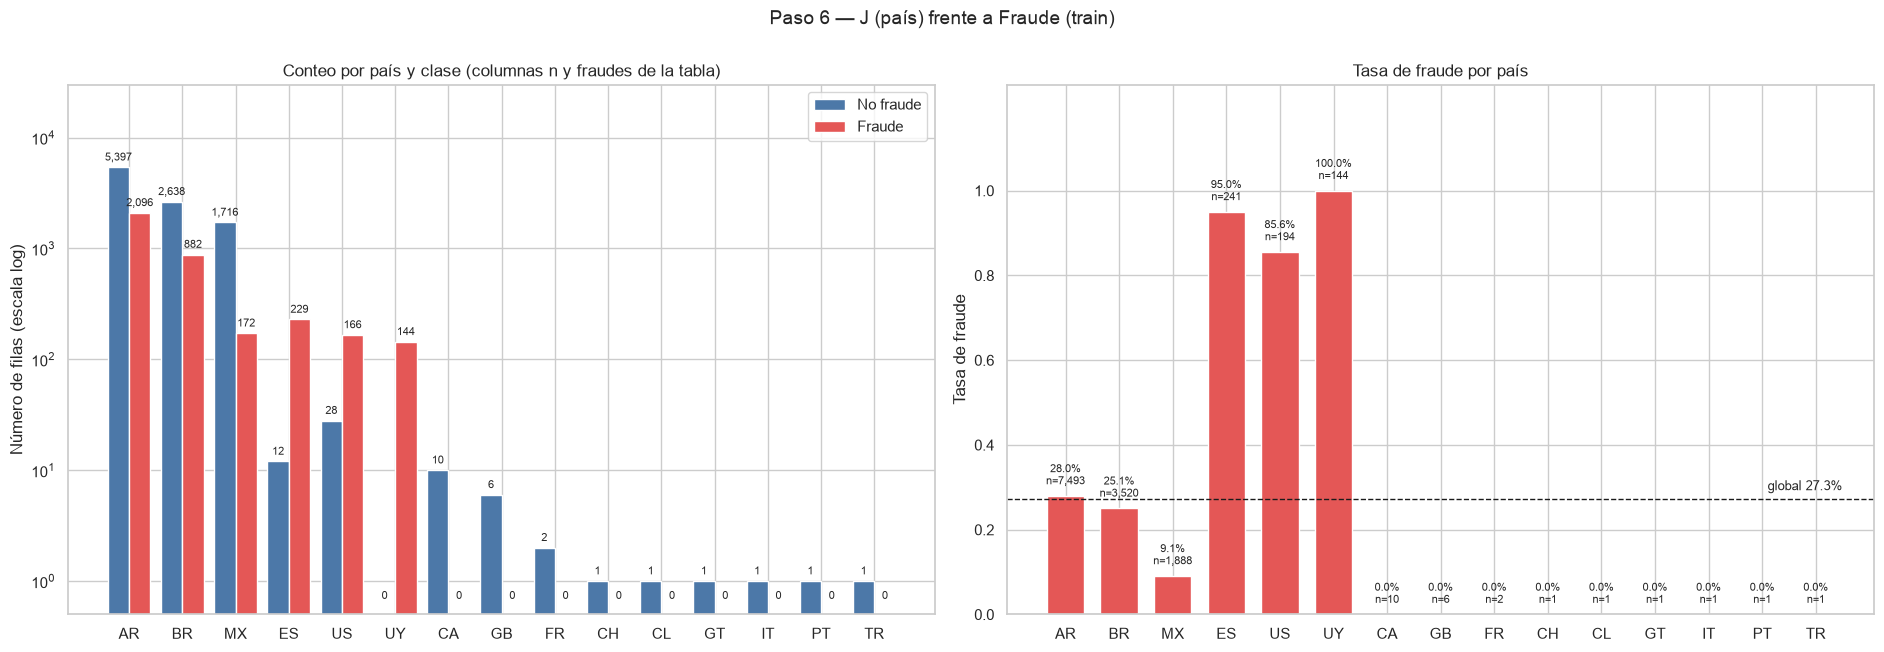

In [24]:
# Gráficos de barras de J (país) vs Fraude, para comparar con la tabla anterior (mismo orden: de más a menos filas).
tj_ = tj.assign(no_fraude=tj["n"] - tj["fraudes"])
x = np.arange(len(tj_)); w = .4
fig, axes = plt.subplots(1, 2, figsize=(19, 6.5))

# (1) Conteos de no fraude y fraude por país (eje Y logarítmico porque AR tiene 7.493 filas y varios países, 1)
ax = axes[0]
b0 = ax.bar(x - w / 2, tj_["no_fraude"], width=w, color="#4C78A8", label="No fraude")
b1 = ax.bar(x + w / 2, tj_["fraudes"], width=w, color="#E45756", label="Fraude")
ax.set_yscale("log"); ax.set_ylim(.5, 3e4)
for bars in (b0, b1):
    for r in bars:
        h = r.get_height()
        ax.text(r.get_x() + r.get_width() / 2, max(h, .6) * 1.15, f"{int(h):,}", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(tj_.index); ax.set_ylabel("Número de filas (escala log)")
ax.set_title("Conteo por país y clase (columnas n y fraudes de la tabla)"); ax.legend()

# (2) Tasa de fraude por país (columna tasa_fraude de la tabla)
ax = axes[1]
tasa = tj_["tasa_fraude"].to_numpy()
ax.bar(x, tasa, color="#E45756", width=.7)
ax.axhline(train[TARGET].mean(), ls="--", color="k", lw=1); ax.text(len(x) - .5, train[TARGET].mean() + .02, f"global {train[TARGET].mean():.1%}", ha="right", fontsize=9)
for xi, t, n in zip(x, tasa, tj_["n"]):
    ax.text(xi, min(t + .02, 1.02) if t > 0 else .02, f"{t:.1%}\nn={n:,}", ha="center", va="bottom", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(tj_.index); ax.set_ylim(0, 1.25); ax.set_yticks(np.linspace(0, 1, 6)); ax.set_ylabel("Tasa de fraude")
ax.set_title("Tasa de fraude por país")
fig.suptitle("Paso 6 — J (país) frente a Fraude (train)", y=1.0, fontsize=14)
plt.tight_layout(); plt.show()

**Lectura del gráfico (compáralo con la tabla)**
- **Izquierda:** AR (5.397 no fraude / 2.096 fraude), BR (2.638 / 882) y MX (1.716 / 172) concentran casi todas las filas. En `UY` no hay ningún no fraude (144 fraudes), en `ES` casi no hay (12 no fraude / 229 fraude) ni en `US` (28 / 166). Los 9 países raros solo tienen barra azul (CA 10, GB 6, FR 2 y seis países con 1).
- **Derecha:** la altura es la columna `tasa_fraude`. MX (9,1%) queda muy por debajo de la línea global (27,3%), AR y BR cerca de ella, y ES, US y UY muy por encima. Los países raros (de 1 a 10 filas) muestran 0%, pero con tan pocas filas eso **no es evidencia de que sean seguros** (cada barra indica su `n`).

In [25]:
# Asociación global J ~ Fraude y la trampa de las categorías raras
chi2, p, dof, esperados = stats.chi2_contingency(pd.crosstab(train["J"], train[TARGET]))
print(f"chi2={chi2:.1f} gl={dof} p={p:.2e} | V de Cramér={np.sqrt(chi2 / len(train)):.3f}")
print(f"Celdas con frecuencia esperada < 5: {(esperados < 5).sum()} de {esperados.size}  -> el chi2 con 15 categorías no es fiable")

# Agrupación propuesta: categorías con >= 100 filas en train se conservan; el resto -> OTRO
UMBRAL = 100
grandes = tj.index[tj["n"] >= UMBRAL].tolist()
Jg = train["J"].where(train["J"].isin(grandes), "OTRO")
tg = train.groupby(Jg)[TARGET].agg(n="size", fraudes="sum")
tg["tasa_fraude"] = tg["fraudes"] / tg["n"]
print("\nCategorías conservadas:", grandes)
print(tg.sort_values("n", ascending=False).round(4).to_string())

chi2g, pg, dofg, esp_g = stats.chi2_contingency(pd.crosstab(Jg, train[TARGET]))
print(f"\nchi2 agrupado={chi2g:.1f} gl={dofg} p={pg:.2e} | V={np.sqrt(chi2g / len(train)):.3f} | celdas esperadas<5: {(esp_g < 5).sum()}")
print("Raras agrupadas en OTRO:", sorted(set(train["J"]) - set(grandes)), "-> su tasa de fraude individual:")
print(train[~train["J"].isin(grandes)].groupby("J")[TARGET].agg(["size", "mean"]).sort_values("size", ascending=False).round(3).to_string())

chi2=1605.9 gl=14 p=0.00e+00 | V de Cramér=0.345
Celdas con frecuencia esperada < 5: 17 de 30  -> el chi2 con 15 categorías no es fiable

Categorías conservadas: ['AR', 'BR', 'MX', 'ES', 'US', 'UY']
         n  fraudes  tasa_fraude
J                               
AR    7493     2096       0.2797
BR    3520      882       0.2506
MX    1888      172       0.0911
ES     241      229       0.9502
US     194      166       0.8557
UY     144      144       1.0000
OTRO    24        0       0.0000

chi2 agrupado=1605.9 gl=6 p=0.00e+00 | V=0.345 | celdas esperadas<5: 0
Raras agrupadas en OTRO: ['CA', 'CH', 'CL', 'FR', 'GB', 'GT', 'IT', 'PT', 'TR'] -> su tasa de fraude individual:
    size   mean
J              
CA    10 0.0000
GB     6 0.0000
FR     2 0.0000
CH     1 0.0000
CL     1 0.0000
GT     1 0.0000
IT     1 0.0000
PT     1 0.0000
TR     1 0.0000


**Conclusión paso 6**
- `J` tiene 15 países en train. Seis tienen ≥ 100 filas: AR (55,5%), BR (26,1%), MX (14,0%), ES (1,8%), US (1,4%) y UY (1,1%). Los otros 9 suman solo 24 filas (CA, GB, FR, CH, CL, GT, IT, PT, TR) y **ninguna es fraude**.
- Tasa de fraude por país: AR 28,0%, BR 25,1%, **MX 9,1%**, **ES 95,0%, US 85,6% y UY 100%**. Asociación global: χ² = 1.605,9; V de Cramér = 0,345 (asociación moderada-alta).
- Con 15 categorías, 17 de 30 celdas tienen frecuencia esperada < 5, así que el χ² no es fiable; agrupando a 7 niveles (los 6 grandes + `OTRO`) no queda ninguna celda < 5 y el resultado es el mismo (V = 0,345).
- **Dos riesgos para el modelado:**
  1. **Separación casi perfecta:** `UY` es 100% fraude y `OTRO` 0%.
  2. **Categorías no vistas:** 4 países (`AU`, `CO`, `KR`, `UA`) aparecen solo en `test`. El pipeline debe manejar categorías nuevas (por ejemplo `OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100)`), enviándolas a `OTRO`.
- **[H10]** Tasas tan extremas por país (ES, US, UY ≥ 85%; MX 9%) sugieren que `J` será muy predictivo aquí, pero puede no generalizar. **Decisión:** en el torneo de modelos se evaluará con y sin `J` y se reportarán ambos resultados.


## Paso 7 — Variables numéricas contra el fraude y entre sí (colinealidad)

**7.1 Cada variable contra el fraude**
- B y S sin el `-1`; C y K solo con dato (el faltante ya se estudió como indicador).

**7.2 Correlograma:** Spearman entre las numéricas y `Fraude`.


In [ ]:
# Numéricas vs Fraude (train): Mann-Whitney -> AUC univariada, Cliff, KS, Spearman, IC bootstrap y corrección BH.
def auc_rank(x, y):
    """AUC de Mann-Whitney: P(valor de un fraude > valor de un no fraude); 0,5 = sin señal."""
    r = rankdata(x); n1 = int(y.sum()); n0 = len(y) - n1
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

def auc_ic(x, y, B=300, seed=SEED):
    """IC95% por bootstrap de la AUC."""
    rng = np.random.default_rng(seed); idx = np.arange(len(x)); aucs = []
    for _ in range(B):
        i = rng.choice(idx, len(idx), replace=True)
        aucs.append(auc_rank(x[i], y[i]))
    return np.percentile(aucs, [2.5, 97.5])

filas = []
for col in NUM:
    s = train[col]; ok = s.notna() & ((s != -1) if col in ("B", "S") else True)
    x, y = s[ok].to_numpy(float), train.loc[ok, TARGET].to_numpy()
    auc = auc_rank(x, y); lo, hi = auc_ic(x, y)
    filas.append(dict(var=col, n=len(x), AUC=auc, IC_inf=lo, IC_sup=hi, cliff=2 * auc - 1,
                      KS=stats.ks_2samp(x[y == 1], x[y == 0]).statistic, spearman=stats.spearmanr(x, y)[0],
                      p_MWU=stats.mannwhitneyu(x[y == 1], x[y == 0]).pvalue))
bi = pd.DataFrame(filas).set_index("var")
bi["q_BH"] = stats.false_discovery_control(bi["p_MWU"].to_numpy(), method="bh")      # corrección por múltiples tests (una por variable)
bi["señal"] = np.where(bi["q_BH"] >= 0.05, "no significativa", np.where(bi["AUC"] > .5, "más valor → más fraude", "más valor → menos fraude"))
bi = bi.reindex((bi["AUC"] - .5).abs().sort_values(ascending=False).index)
show = bi[['n', 'AUC', 'spearman', 'señal']].copy()
show

,n,AUC,spearman,señal
var,,,,
B,13413,0.6965,0.3042,más valor → más fraude
S,13392,0.6621,0.2495,más valor → más fraude
K,3222,0.3547,-0.2419,más valor → menos fraude
M,13504,0.5674,0.1255,más valor → más fraude
P,13504,0.5630,0.1137,más valor → más fraude
Monto,13504,0.4655,-0.0533,más valor → menos fraude
C,10903,0.5308,0.0487,más valor → más fraude
A,13504,0.5217,0.0531,más valor → más fraude
N,13504,0.5179,0.0641,más valor → más fraude


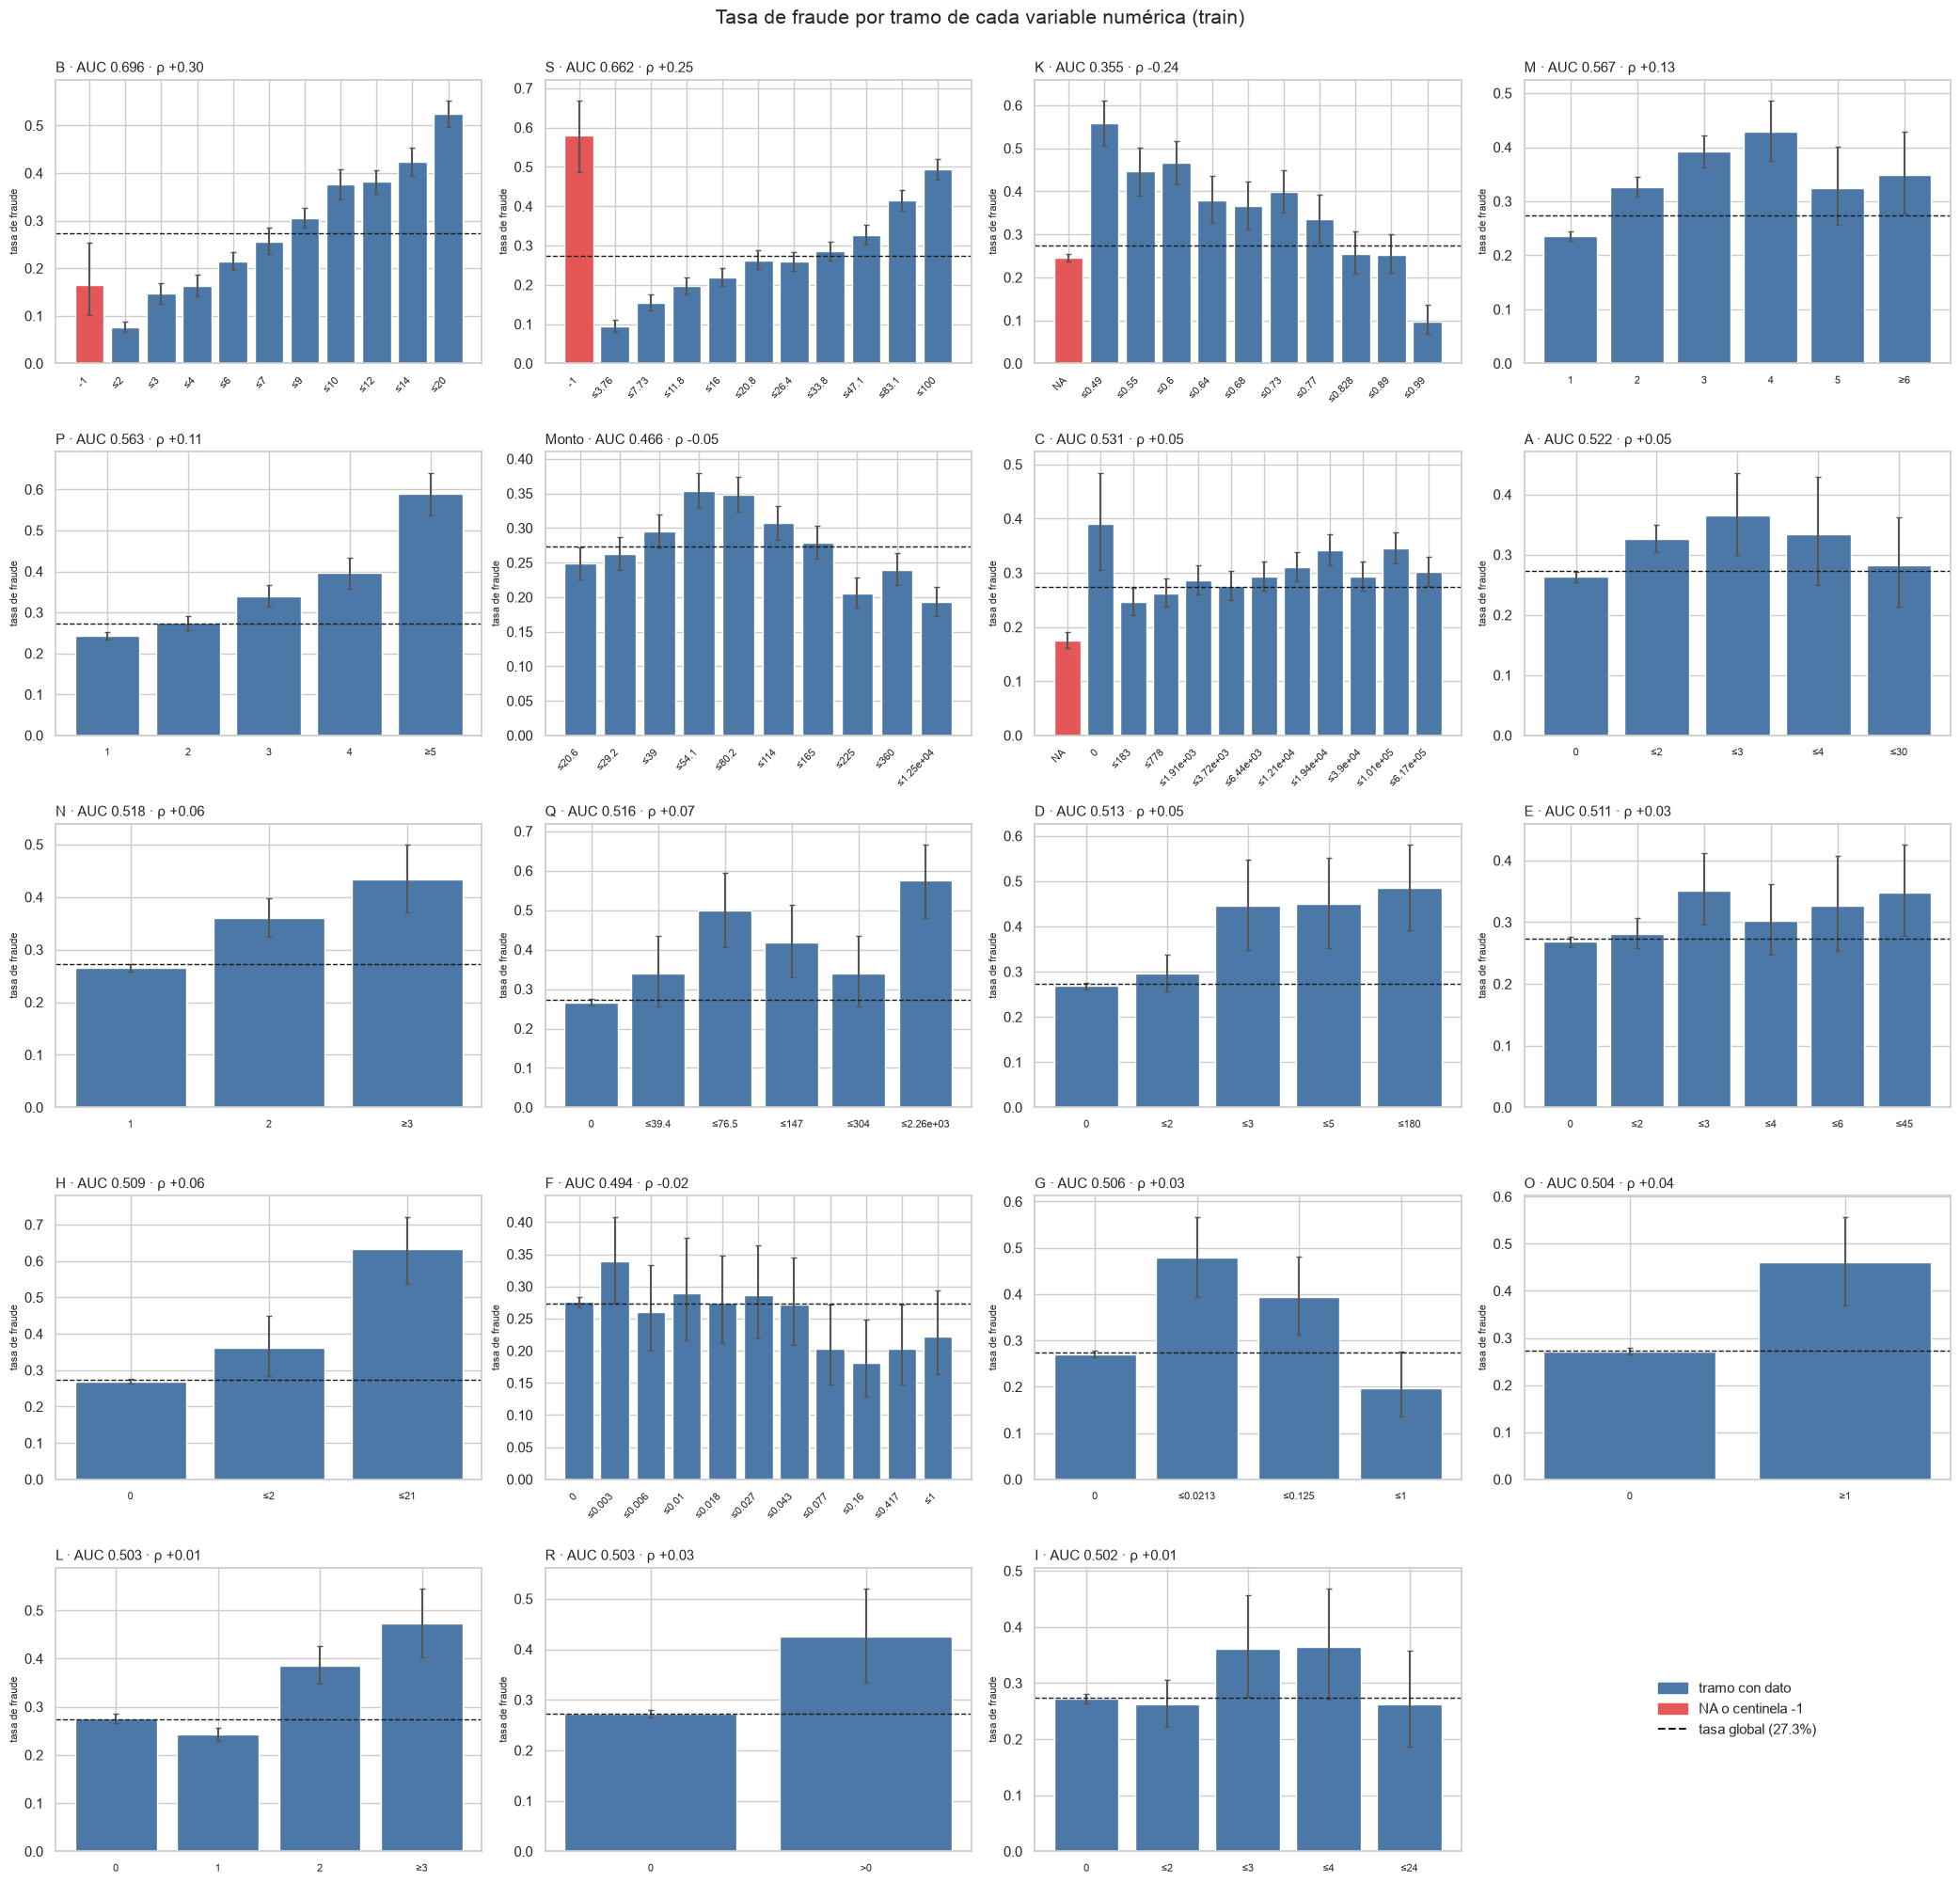

In [29]:
# Comportamiento de cada variable numérica frente al fraude: tasa de fraude por tramo (IC95% de Wilson).

def tramos(s, nombre):
    out = pd.Series("NA", index=s.index, dtype=object)
    neg = (s == -1) if nombre in ("B", "S") else pd.Series(False, index=s.index)
    ok = s.notna() & ~neg; v = s[ok]; out[neg] = "-1"
    orden = [l for l, hay in (("NA", (~ok & ~neg).any()), ("-1", neg.any())) if hay]
    if v.nunique() <= 12:                                   # discreta: un tramo por valor; la cola con < 50 filas se agrupa en ">= k"
        cuentas = v.value_counts().sort_index(); tope = cuentas[cuentas >= 50].index.max()
        for x in cuentas.index[cuentas.index < tope]:
            lab = f"{x:g}"; out[ok & (s == x)] = lab; orden.append(lab)
        lab = f"≥{tope:g}"; out[ok & (s >= tope)] = lab; orden.append(lab)
    else:                                                   # continua / muy dispersa: cero propio y tramos de los positivos con >= 100 filas cada uno
        if (v == 0).any(): out[ok & (s == 0)] = "0"; orden.append("0")
        pos = ok & (s > 0); nb = min(10, int(pos.sum()) // 100)
        if nb <= 1:
            out[pos] = ">0"; orden.append(">0")
        else:
            q = pd.qcut(s[pos], nb, duplicates="drop")
            for itv in q.cat.categories:
                lab = f"≤{itv.right:.3g}"; out[pos & (s > itv.left) & (s <= itv.right)] = lab; orden.append(lab)
    return out, orden

glob = train[TARGET].mean()
fig, axes = plt.subplots(5, 4, figsize=(21, 20))
resumen7 = []
for ax, col in zip(axes.ravel(), bi.index):
    etiq, orden = tramos(train[col], col)
    g = train.groupby(etiq)[TARGET].agg(n="size", k="sum").reindex(orden)
    tasa = (g["k"] / g["n"]).to_numpy(); ic = np.array([wilson(k, n) for k, n in zip(g["k"], g["n"])])
    color = ["#E45756" if l in ("NA", "-1") else "#4C78A8" for l in orden]
    ax.bar(range(len(orden)), tasa, color=color, yerr=[tasa - ic[:, 0], ic[:, 1] - tasa], ecolor="#555", capsize=2)
    ax.axhline(glob, ls="--", color="k", lw=1)
    ax.set_xticks(range(len(orden))); ax.set_xticklabels(orden, rotation=45 if len(orden) > 8 else 0, ha="right" if len(orden) > 8 else "center", fontsize=8)
    ax.set_title(f"{col} · AUC {bi.loc[col, 'AUC']:.3f} · ρ {bi.loc[col, 'spearman']:+.2f}", fontsize=11, loc="left")
    ax.set_ylabel("tasa de fraude", fontsize=8); ax.set_ylim(0, min(1, np.nanmax(ic[:, 1]) * 1.08))
    dato = np.array([l not in ("NA", "-1") for l in orden]); grandes = (g["n"] >= 100).to_numpy() & dato
    resumen7.append((col, len(orden), tasa[dato][0], tasa[dato][-1], tasa[grandes].min(), tasa[grandes].max()))
leyenda = axes.ravel()[len(bi)]; leyenda.axis("off")
leyenda.legend(handles=[Patch(color="#4C78A8", label="tramo con dato"), Patch(color="#E45756", label="NA o centinela -1"),
                        Line2D([0], [0], color="k", ls="--", label=f"tasa global ({glob:.1%})")], loc="center", fontsize=11, frameon=False)
fig.suptitle("Tasa de fraude por tramo de cada variable numérica (train)", y=1.0, fontsize=15)
plt.tight_layout(); plt.show()

# Tramos: NA y centinela -1 (rojo) si existen; discretas (<= 12 valores): un tramo por valor y la cola rara agrupada en ">= k";
# resto: el cero y tramos de los positivos con al menos 100 filas cada uno (hasta 10).
# Líneas discontinuas = tasa global. Los paneles siguen el orden de la tabla del paso 7 (mayor a menor |AUC - 0,5|).

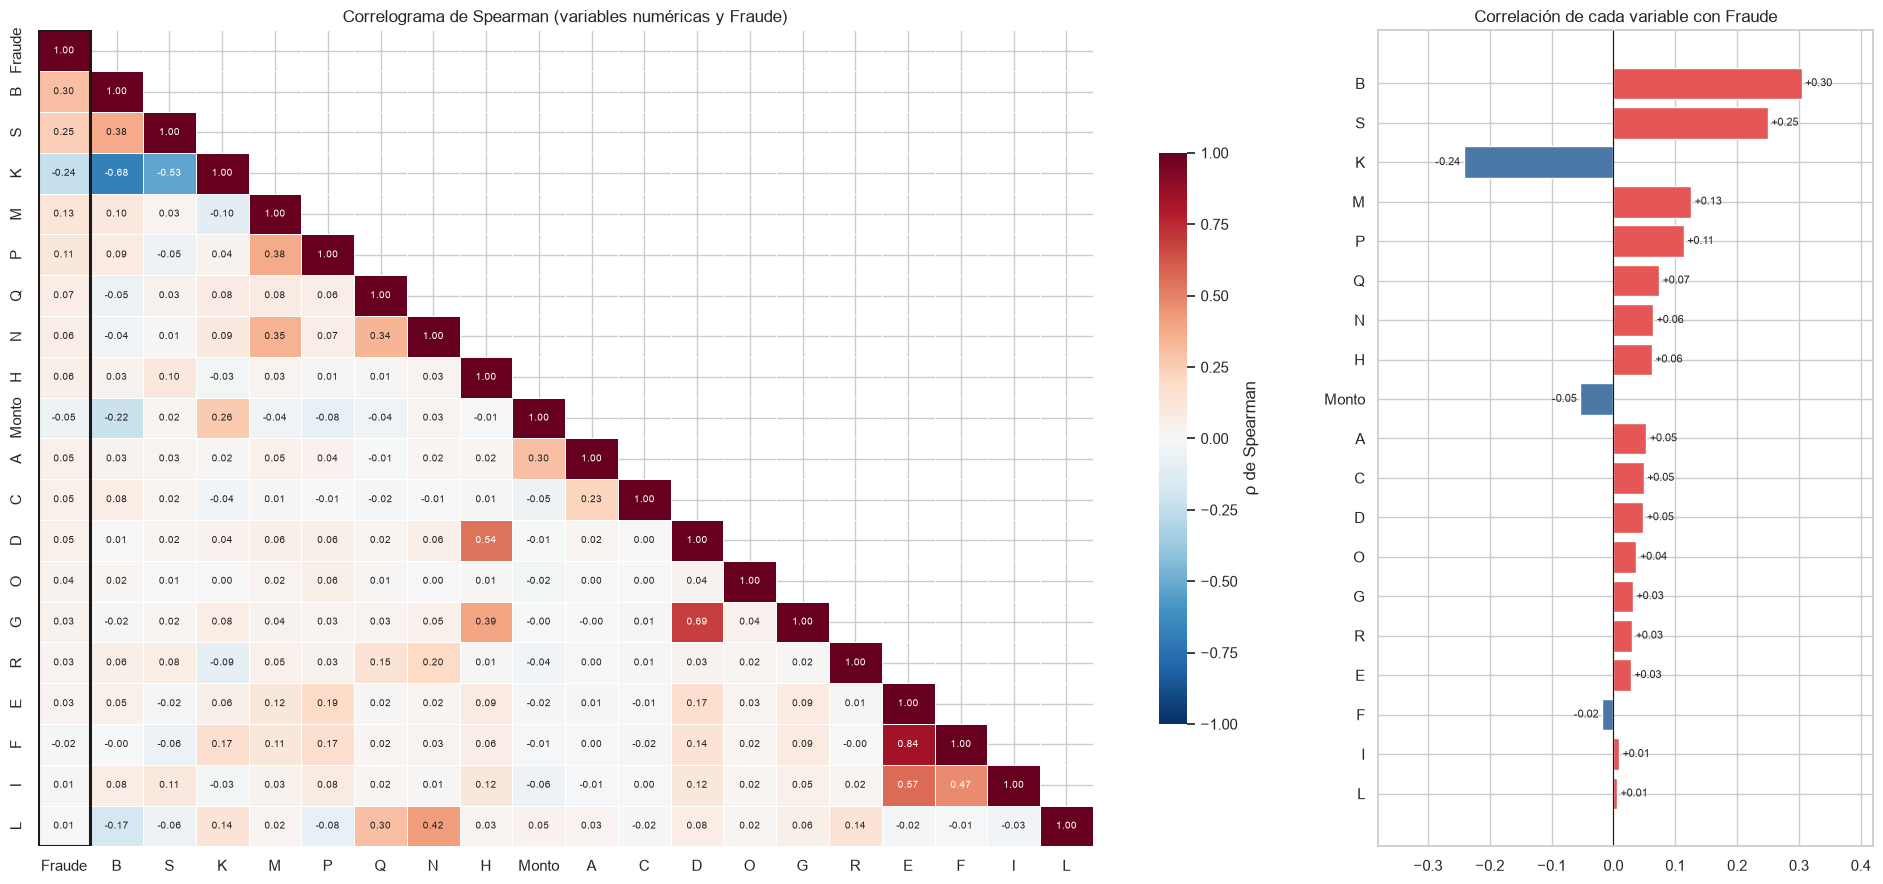

Pares entre variables (sin Fraude) con |rho| >= 0,50:
  E-F: +0.84
  D-G: +0.69
  B-K: -0.68
  E-I: +0.57
  H-D: +0.54
  S-K: -0.53


In [ ]:
# Correlograma: variables numéricas + Fraude (Spearman, pairwise; centinelas -1 de B y S como NaN).
# Se ordena por |correlación con Fraude|; la primera columna es la correlación de cada variable con Fraude.
# X (paso 5) ya tiene las numéricas con los centinelas -1 de B y S como NaN.
corr = X.assign(**{TARGET: train[TARGET]}).corr(method="spearman")
orden = [TARGET] + corr[TARGET].drop(TARGET).abs().sort_values(ascending=False).index.tolist()
corr = corr.loc[orden, orden]

fig, (ax, axb) = plt.subplots(1, 2, figsize=(19, 9), gridspec_kw={"width_ratios": [3.2, 1.2]})
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", annot_kws={"size": 7}, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            linewidths=.4, linecolor="white", ax=ax, cbar_kws={"shrink": .7, "label": "ρ de Spearman"})
ax.add_patch(Rectangle((0, 0), 1, len(corr), fill=False, ec="k", lw=2.2))
ax.set_title("Correlograma de Spearman (variables numéricas y Fraude)")

rho = corr[TARGET].drop(TARGET).iloc[::-1]
axb.barh(rho.index, rho.values, color=np.where(rho.values > 0, "#E45756", "#4C78A8"))
for yi, v in enumerate(rho.values): axb.text(v + (.006 if v >= 0 else -.006), yi, f"{v:+.2f}", va="center", ha="left" if v >= 0 else "right", fontsize=8)
axb.axvline(0, color="k", lw=.8); axb.set_xlim(-.38, .42)
axb.set_title("Correlación de cada variable con Fraude")
plt.tight_layout(); plt.show()

print("Pares entre variables con |rho| >= 0,50:")
for a, b, r in sorted([(a, b, corr.loc[a, b]) for i, a in enumerate(orden[1:]) for b in orden[1:][i + 1:] if abs(corr.loc[a, b]) >= .5], key=lambda t: -abs(t[2])):
    print(f"  {a}-{b}: {r:+.2f}")

**Lectura de los gráficos del paso 7**

*Correlograma (Spearman, ordenado por correlación con Fraude; la primera columna es la de Fraude):*
- Correlación con Fraude: `B` +0,30, `S` +0,25, `K` −0,24, `M` +0,13 y `P` +0,11; las demás tienen |ρ| ≤ 0,07.
- **Entre variables:** `K`–`B` −0,68 y `K`–`S` −0,53 (`K` está ligada a las dos más predictivas.)
- La correlación mide solo asociación monótona: no ve `L` ni `Monto`, que los gráficos de tramos sí muestran.

**Conclusión paso 7**
- 17 de 19 variables son significativas;`L` (q = 0,51) e `I` (q = 0,31) no tienen señal monótona.
- **Pocas variables tienen un efecto relevante:** `B` (AUC 0,697; IC 0,686–0,705), `S` (0,662) y `K` (0,355; invertida, equivale a 0,645) son las más separadoras; les siguen `M` (0,567) y `P` (0,563). Para todas las demás |AUC − 0,5| < 0,05 (por ejemplo `Monto` 0,466, `C` 0,531, `A` 0,522): son estadísticamente detectables pero débiles por sí solas. `R` tiene q = 5e-4 y AUC = 0,503: significancia sin relevancia.
- Dirección: a mayor `B`, `S`, `M`, `P` más fraude; a mayor `K` menos fraude; el fraude tiende a ocurrir con **montos algo menores** (AUC de `Monto` 0,466).
- Las variables dispersas (`A`, `D`, `E`, `G`, `H`, `O`, `Q`, `R`) casi no se ven con Mann-Whitney porque la mayoría son ceros; se ven mejor en los gráficos de tasa por tramo (el salto está entre cero y positivo).
- Una señal univariada **no** equivale a importancia en el modelo: las variables pueden redundar entre sí (ver colinealidad abajo).

**Colinealidad**
- Pares más correlacionados (Spearman): `E`–`F` 0,84, `G`–`D` 0,69, `K`–`B` −0,68, `E`–`I` 0,57, `D`–`H` 0,54 y `K`–`S` −0,53.
- **Decisión:** no se elimina nada por colinealidad.

## Paso 8 — Variables discretas: ¿numéricas o categóricas?

Se agrupa la cola (valores con < 50 filas → «≥ k») y se comparan dos tests: **chi² global** (cualquier asociación) y **tendencia de Cochran-Armitage** (asociación lineal con el orden). Además se cuentan los cambios de dirección de la tasa de fraude entre niveles consecutivos: si hay 0, la relación es monótona. Ese conteo es sensible al ruido en niveles pequeños, por eso se confirma con los gráficos.


In [39]:
# PASO 8. Variables discretas: ¿numérica monótona o categórica? Se agrupa la cola (valores con < 50 filas -> ">= k")
DISC = ["L", "M", "N", "O", "P", "A", "D", "E", "H", "I", "B"]

def capear(s, minimo=50):
    s = s.where(s != -1)                                   # B: se excluye el centinela
    cuentas = s.value_counts().sort_index()
    ok = cuentas[cuentas >= minimo].index
    tope = ok.max()
    return s.clip(upper=tope), tope

def cochran_armitage(x, y):
    """z de tendencia lineal en la proporción de fraude según el valor ordinal x."""
    p = y.mean(); n = pd.Series(1, index=x.index).groupby(x).sum(); r = y.groupby(x).sum()
    xs = n.index.to_numpy(float)
    num = (xs * (r.to_numpy() - n.to_numpy() * p)).sum()
    den = np.sqrt(p * (1 - p) * ((n.to_numpy() * xs**2).sum() - (n.to_numpy() * xs).sum()**2 / n.sum()))
    z = num / den
    return z, 2 * stats.norm.sf(abs(z))

filas = []
for col in DISC:
    xc, tope = capear(train[col]); ok = xc.notna(); x, y = xc[ok], train.loc[ok, TARGET]
    tabla = pd.crosstab(x, y)
    chi2, p_chi, dof, esp = stats.chi2_contingency(tabla)
    z, p_tr = cochran_armitage(x, y)
    # monotonía: nº de cambios de dirección en la serie de tasas por nivel (cada nivel ya tiene >= 50 filas)
    tasas = y.groupby(x).mean().to_numpy(); cambios = int((np.diff(np.sign(np.diff(tasas))) != 0).sum())
    filas.append(dict(var=col, niveles=len(tabla), tope=f">={int(tope)}", chi2_p=p_chi, trend_z=z, trend_p=p_tr,
                      V=np.sqrt(chi2 / (len(x) * (min(tabla.shape) - 1))), cambios_de_dirección=cambios))
dd = pd.DataFrame(filas).set_index("var")
dd["lectura"] = np.where(dd["chi2_p"] >= .05, "sin asociación",
                  np.where((dd["trend_p"] < .05) & (dd["cambios_de_dirección"] == 0), "monótona: numérica",
                           "no monótona: probar también como categórica"))
show = dd.copy(); show["chi2_p"] = show["chi2_p"].map("{:.1e}".format); show["trend_p"] = show["trend_p"].map("{:.1e}".format)
show.sort_values("V", ascending=False)

,niveles,tope,chi2_p,trend_z,trend_p,V,cambios_de_dirección,lectura
var,,,,,,,,
B,19,>=19,1.4e-260,35.3616,6.7e-274,0.3088,4,no monótona: probar también como categórica
P,5,>=5,4.0e-62,16.1086,2.2e-58,0.1472,0,monótona: numérica
M,6,>=6,1.7e-46,12.8652,7.1e-38,0.1289,2,no monótona: probar también como categórica
L,4,>=3,1.6e-20,3.5686,3.6e-04,0.0840,1,no monótona: probar también como categórica
N,3,>=3,1.3e-13,7.6846,1.5e-14,0.0663,0,monótona: numérica
D,5,>=4,3.2e-11,7.1654,7.8e-13,0.0638,0,monótona: numérica
H,2,>=1,1.5e-12,7.1524,8.5e-13,0.0609,0,monótona: numérica
A,5,>=4,1.6e-08,5.3902,7.0e-08,0.0558,1,no monótona: probar también como categórica
E,9,>=8,6.8e-03,3.7366,1.9e-04,0.0396,4,no monótona: probar también como categórica


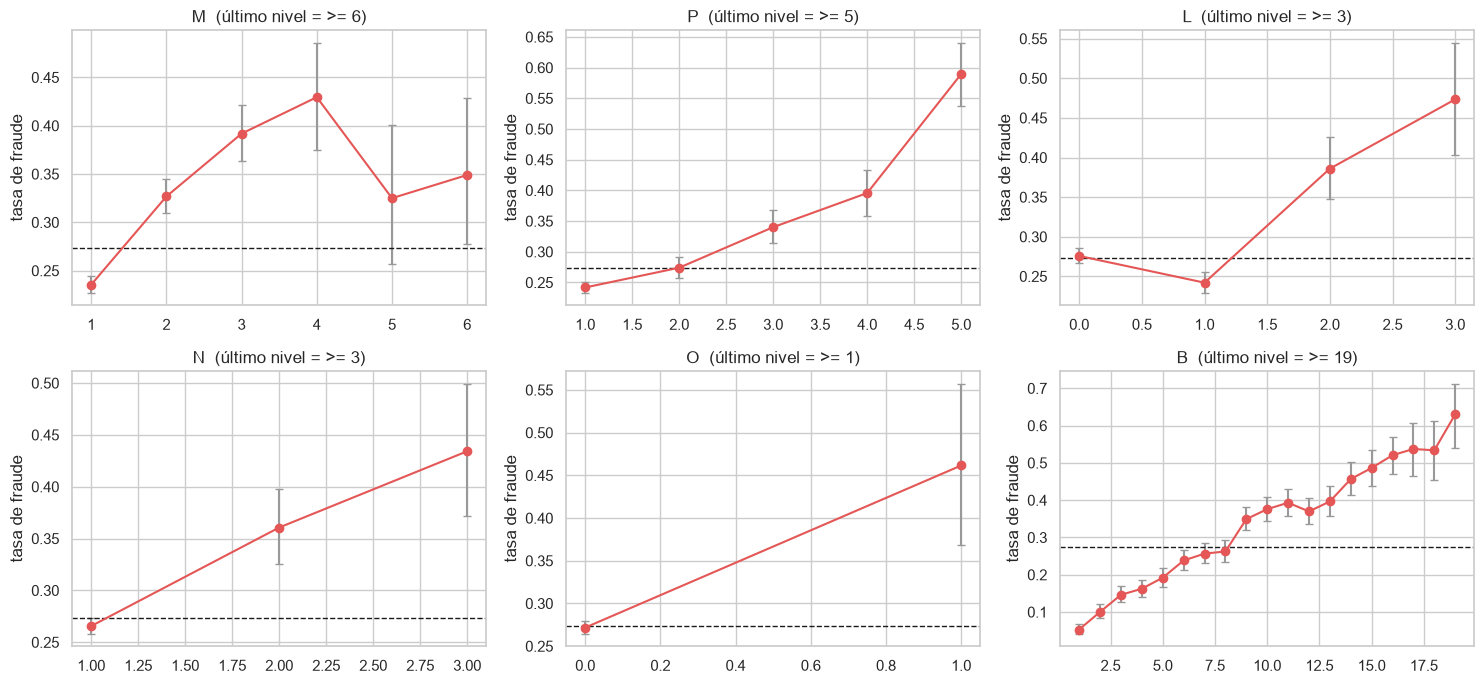

L | 0: 27.6% (n=8712)  1: 24.2% (n=4021)  2: 38.6% (n=583)  3: 47.3% (n=188)
M | 1: 23.6% (n=9073)  2: 32.7% (n=2745)  3: 39.2% (n=1072)  4: 43.0% (n=305)  5: 32.5% (n=160)  6: 34.9% (n=149)
N | 1: 26.6% (n=12605)  2: 36.1% (n=671)  3: 43.4% (n=228)
O | 0: 27.2% (n=13400)  1: 46.2% (n=104)
P | 1: 24.2% (n=8614)  2: 27.4% (n=2715)  3: 34.0% (n=1182)  4: 39.6% (n=647)  5: 59.0% (n=346)
A | 0: 26.3% (n=11401)  1: 31.6% (n=1232)  2: 35.7% (n=442)  3: 36.5% (n=189)  4: 30.4% (n=240)
E | 0: 26.8% (n=11407)  1: 27.6% (n=935)  2: 29.6% (n=368)  3: 35.2% (n=256)  4: 30.2% (n=242)  5: 39.7% (n=58)  6: 27.5% (n=80)  7: 25.0% (n=16)  8: 35.9% (n=142)


In [40]:
# Tasa de fraude por nivel de las discretas con asociación
mostrar = ["M", "P", "L", "N", "O", "B"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.ravel(), mostrar):
    xc, tope = capear(train[col]); ok = xc.notna()
    g = train.loc[ok].groupby(xc[ok])[TARGET].agg(["size", "sum"])
    ci = np.array([wilson(k, n) for k, n in zip(g["sum"], g["size"])]); tasa = g["sum"] / g["size"]
    ax.errorbar(g.index, tasa, yerr=[tasa - ci[:, 0], ci[:, 1] - tasa], fmt="o-", color="#E45756", ecolor="#999", capsize=3)
    ax.axhline(train[TARGET].mean(), ls="--", color="k", lw=1)
    ax.set_title(f"{col}  (último nivel = >= {int(tope)})"); ax.set_ylabel("tasa de fraude"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

# Tasas por nivel (valor, n, tasa de fraude)
for col in ["L", "M", "N", "O", "P", "A", "E"]:
    xc, tope = capear(train[col]); ok = xc.notna()
    g = train.loc[ok].groupby(xc[ok])[TARGET].agg(n="size", tasa="mean")
    print(col, "|", "  ".join(f"{int(i)}: {r.tasa:.1%} (n={int(r.n)})" for i, r in g.iterrows()))

**Conclusión paso 8**
- **`L` es la lección clave:** Mann-Whitney no ve nada (AUC 0,503; p = 0,51), pero el chi² es muy significativo (p = 1,6e-20). La relación tiene forma de **U**: 27,6% con `L`=0, 24,2% con 1, 38,6% con 2 y 47,3% con ≥ 3. Un test monótono la habría descartado por error. **Decisión:** tratarla como categórica (o dejar que los árboles la capten).
- **`P`** es la discreta más limpia: sube de 24,2% (`P`=1) a 59,0% (`P` ≥ 5; n = 346), monótona, V = 0,147. Tratar como numérica.
- **`N`** (26,6% → 36,1% → 43,4%), **`D`**, **`H`** y **`O`** (27,2% vs 46,2%) son monótonas: numéricas.
- **`M`** sube hasta 43,0% en `M`=4 y luego se estanca (32,5% y 34,9% con n = 160 y 149; IC amplios). **Decisión:** agrupar en «≥ 4» o dejarla a los árboles.
- **`A`** y **`E`** tienen asociación débil y irregular; **`I`** no tiene asociación (chi² p = 0,17).
- **`B`** (19 niveles; V = 0,309; z de tendencia = 35) es la discreta más asociada; el conteo de cambios de dirección (4) refleja ruido en niveles poco poblados, no una forma distinta.


## Paso 9 — Conclusiones del EDA y ficha de variables


In [ ]:
# PASO 9. Ficha de variables: señal + tratamiento propuesto para el modelado
TRAT = {
 "B": ("discreta 0-20 (+ centinela -1)", "numérica; indicador B==-1", "señal alta"),
 "S": ("continua 0-100 (+ centinela -1)", "numérica; indicador S==-1", "señal alta"),
 "K": ("continua 0-1, 76% NaN", "indicador K_falta; mediana o NaN nativo (árboles)", "señal alta (invertida)"),
 "C": ("continua sesgada, 19% NaN", "indicador C_falta; imputada con la mediana de train; log1p en lineales", "débil"),
 "M": ("discreta 1-13", "agrupar >= 4", "media"),
 "P": ("discreta 1-41", "numérica; tope en 5", "media"),
 "L": ("discreta 0-7, forma de U", "categórica (0, 1, 2, >=3)", "media (no monótona)"),
 "N": ("discreta 1-10", "numérica; tope en 3", "débil"),
 "A": ("conteo, 84% ceros", "indicador A>0 + log1p", "débil"),
 "D": ("conteo, 94% ceros", "indicador D>0 + log1p", "débil"),
 "E": ("conteo, 84% ceros; colineal con F", "indicador E>0 + log1p; elegir E o F", "débil"),
 "F": ("proporción, 88% ceros; colineal con E", "evaluar eliminar si E aporta lo mismo", "débil/nula"),
 "G": ("proporción, 97% ceros", "indicador G>0", "débil"),
 "H": ("conteo, 98% ceros", "indicador H>0", "débil-media"),
 "I": ("conteo, 95% ceros", "candidata a descartar (sin asociación)", "nula"),
 "O": ("conteo, 99% ceros", "indicador O>0", "débil"),
 "Q": ("monto, 96% ceros, cola larga", "indicador Q>0 + log1p", "débil-media"),
 "R": ("monto, 99% ceros, cola larga", "indicador R>0", "débil"),
 "Monto": ("continua, muy sesgada", "log1p (lineales)", "débil"),
 "J": ("categórica 15 niveles", "6 países + OTRO; categorías no vistas -> OTRO; evaluar con y sin J", "muy alta (¿artefacto de muestreo?)"),
}
ficha = pd.DataFrame(TRAT, index=["tipo", "tratamiento", "señal"]).T
ficha["AUC_univ"] = bi["AUC"]            # J es categórica: no tiene AUC univariada
ficha["spearman"] = bi["spearman"]
ficha = ficha.reindex((ficha["AUC_univ"] - .5).abs().sort_values(ascending=False, na_position="first").index)
ficha[["tipo", "tratamiento", "señal", "AUC_univ", "spearman"]]

### Hallazgos clave
1. **Datos:** 16.880 filas × 21 columnas y 27,3% de fraude (muestra enriquecida respecto a producción, **[H]**). El archivo viene ordenado por clase (las primeras 1.000 filas son 100% fraude). `Monto`, `Q` y `R` traen coma de miles y se leen con `thousands=','`. Solo `K` (76%) y `C` (19%) tienen faltantes, y su ausencia se asocia con el fraude (χ², p < 1e-35).
2. **Señal:** entre las numéricas, `B` (AUC univariada 0,697), `S` (0,662), `K` (0,355: a mayor `K`, menos fraude), `M` (0,567) y `P` (0,563) concentran la señal (7.1). `J` (país) es la variable más asociada al fraude (V de Cramér = 0,345; de 9,1% en MX a 85–100% en US, ES y UY). Las demás son débiles por sí solas.
3. **No linealidades** (7.1 y paso 8): `L` tiene forma de U (27,6% con 0, 24,2% con 1, 38,6% con 2 y 47,3% con ≥ 3), `Monto` de U invertida (entre 19,2% y 35,4% según el tramo) y `M` sube hasta `M` = 4 y se estanca. Una AUC o una correlación no las captan: favorecen árboles/boosting o términos no lineales en un modelo lineal.
4. **Colas = señal:** no se eliminan outliers (`P` > p99: 93,2% de fraude frente a 27,1%); las 10 variables con ≥ 84% de ceros se representan con un indicador `x > 0`.
5. **Colinealidad moderada** (7.2): los pares más correlacionados son `E`–`F` (0,84), `G`–`D` (0,69) y `K`–`B` (−0,68); `K` también se relaciona con `S` (−0,53) **[H11]**. No se elimina nada por colinealidad.

### Riesgos
- **Muestra enriquecida:** PR-AUC y precisión no se trasladan a producción; el umbral real dependerá de la prevalencia y del costo.
- **`J` posible artefacto de muestreo [H10]** y **`B`/`S` posible fuga [H12]** (hay que confirmar con quien entrega los datos que están disponibles al decidir): se evaluará el modelo con y sin `J`.
- **Sin variable temporal:** no hay validación fuera de tiempo.
- **Variables anónimas:** las hipótesis [H] no se pueden confirmar.
- **Alcance del EDA:** no incluye interacciones entre variables, IV/información mutua, estabilidad train–test ni la comprobación de si `C` identifica entidades. Ninguna decisión de este resumen depende de ellas.

### Plan para el modelado (siguiente fase)
1. Pipeline de scikit-learn: imputación (mediana) + indicadores (`C_falta`, `K_falta`, `B==-1`, `S==-1`, `x>0`), `log1p` en modelos lineales, agrupación de `J`, `M` (≥ 4), `L` categórica y `Monto` por tramos; todo ajustado solo con train.
2. Validación cruzada estratificada de 5 folds sobre train; test sellado hasta el final.
3. Torneo de modelos: regresión logística regularizada, Random Forest y boosting (HistGradientBoosting / XGBoost / LightGBM), cada uno con y sin `J`.
4. Métricas: PR-AUC (línea base 0,273), ROC-AUC, recall a precisión fija, calibración y selección del umbral por costo.

## Resumen de decisiones (pasos 0–9)

| # | Decisión | Evidencia |
|---|---|---|
| 1 | Leer con `thousands=','` (`Monto`, `Q` y `R` traen coma de miles) | `df.dtypes` (paso 0): las tres quedan numéricas |
| 2 | Partir 80/20 estratificado, `random_state=42`; explorar solo train | 27,32% vs 27,31% de fraude |
| 3 | Nunca partir ni imputar por posición | Primeras 1.000 filas = 100% fraude |
| 4 | Conservar el `-1` de `B` y `S` con indicador propio | `S = -1`: 58,0% de fraude; `B = -1`: 16,5%; resto ≈ 27% |
| 5 | Métrica principal PR-AUC (línea base 0,273) | Tasa de fraude 27,32%; razón 2,66:1 |
| 6 | Conservar `K` y `C`; indicadores `K_falta` y `C_falta`; imputar `C` con la mediana de train (`train_imp`, `test_imp`) | χ² con p < 1e-35 en ambas |
| 7 | No eliminar outliers; indicador `x > 0` en las 10 variables con ≥ 84% de ceros; `log1p` en `Monto` y `C` solo para modelos lineales | Fraude en la cola > p99: `P` 93,2%, `Q` 52,9%; `Monto` sin efecto (p = 0,37) |
| 8 | `J`: 6 países + `OTRO`; categorías no vistas → `OTRO`; regularizar; evaluar con y sin `J` | `UY` 100% y `OTRO` 0%; 4 países solo en test; V = 0,345 |
| 9 | Variables con señal univariada relevante: `B`, `S`, `K`, `M`, `P`; el resto es débil por sí solo | AUC 0,56–0,70 con IC95% bootstrap; 17 de 19 significativas tras BH |
| 10 | `L` como categórica; `M` agrupada en ≥ 4; `Monto` por tramos en modelos lineales | `L`: AUC 0,503 (p = 0,51) pero χ² p = 1,6e-20; `M` 43,0% → 32–35%; `Monto` 19,2%–35,4% entre tramos |
| 11 | No eliminar por colinealidad; regularizar los modelos lineales | Pares con |ρ| ≥ 0,5 en el correlograma (7.2); no se descarta ninguna variable |
| 12 | `I` es candidata a descartar | AUC 0,502 (q = 0,31) y χ² p = 0,17 |
| 13 | Confirmar que `B` y `S` están disponibles al decidir | Señal muy alta (AUC 0,70 y 0,66) y centinelas informativos [H12] |

**Siguiente fase:** preparar el pipeline de preprocesamiento y el torneo de modelos (ver «Plan para el modelado» arriba).